# Assignment 3 — Natural Language Processing
## Полное решение четырёх заданий

**Как запустить:** Python 3.10–3.12, Jupyter или Google Colab → **Run all / Выполнить всё**.
Для первого запуска нужен интернет; GPU не требуется. Данные и модели загружаются автоматически
и кешируются в `nlp_assignment_data/`, результаты — в `nlp_assignment_results/`.
Пять приложенных статей уже встроены в этот файл: отдельно загружать их не нужно.
При желании положите свои `article1.txt` … `article5.txt` рядом с ноутбуком — они заменят встроенные.

1. **Тональность:** VADER и TF-IDF + Logistic Regression; три класса, train/validation/test,
   подбор параметров, метрики, ошибки, облака слов и веса признаков.
2. **Суммаризация:** по 3 предложения из первых 3 статей, общий список из 6 предложений;
   иерархическая абстрактивная сводка по всем 5 статьям с предобученной T5-small.
3. **Песни:** 4 жанра × 10 уникальных текстов, частоты, категории, редкие слова.
4. **Язык:** WiLI-2018, 6 языков × 800 примеров, 80/20, 8 классических моделей и fastText lid.176,
   анализ ошибок и устойчивости на коротких текстах.
5. Ответы на все 15 контрольных вопросов.

Все случайные операции фиксированы (`SEED=42`). Метрики вычисляются кодом, а не заданы вручную.
Внешние материалы используются как данные; текст статей не исполняется как инструкции.

In [1]:
# Установка выполняется до импорта numpy/pandas.
import os, sys, subprocess
if os.environ.get("NLP_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "numpy==1.26.4", "pandas==2.2.3", "scikit-learn==1.5.2",
        "nltk==3.9.1", "matplotlib>=3.9,<4", "wordcloud>=1.9,<2",
        "requests>=2.32,<3", "transformers==4.46.3", "sentencepiece>=0.2,<0.3",
        "huggingface_hub>=0.26,<1", "torch>=2.2",
        "optimum==1.23.3", "onnx==1.17.0", "onnxruntime==1.20.1", "fasttext-wheel==0.9.2",
        "rouge-score==0.1.2"])
print("Зависимости установлены. При конфликте с ранее импортированным numpy перезапустите ядро и Run all.")

Зависимости установлены. При конфликте с ранее импортированным numpy перезапустите ядро и Run all.


In [2]:
from pathlib import Path
from collections import Counter
from functools import lru_cache
import re, json, hashlib, random, html, unicodedata, warnings, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.metrics.pairwise import cosine_similarity
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
DATA = Path('nlp_assignment_data'); DATA.mkdir(exist_ok=True)
RESULTS = Path('nlp_assignment_results'); RESULTS.mkdir(exist_ok=True)
os.environ.setdefault('HF_HOME', str((DATA / 'hf_cache').resolve()))
NLTK_DIR = DATA / 'nltk'; NLTK_DIR.mkdir(exist_ok=True)
nltk.data.path.insert(0, str(NLTK_DIR.resolve()))
for resource in ['punkt_tab', 'wordnet', 'averaged_perceptron_tagger_eng', 'stopwords', 'vader_lexicon']:
    if not nltk.download(resource, download_dir=str(NLTK_DIR), quiet=True, raise_on_error=True):
        raise RuntimeError(f'Не удалось загрузить NLTK: {resource}')

session = requests.Session()
session.mount('https://', HTTPAdapter(max_retries=Retry(total=3, backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504])))
DOWNLOAD_LOG = {}
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''): h.update(block)
    return h.hexdigest()

def fetch(url, path, expected_sha256=None):
    """HTTPS + атомарная запись; при заданном хеше проверяется также кеш."""
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists() and expected_sha256 and sha256_file(path) != expected_sha256:
        raise ValueError(f'Контрольная сумма кеша не совпала: {path}. Удалите этот файл и повторите.')
    if not path.exists():
        tmp = path.with_suffix(path.suffix + '.part')
        with session.get(url, stream=True, timeout=(20, 180)) as response:
            response.raise_for_status()
            with open(tmp, 'wb') as f:
                for block in response.iter_content(1024 * 1024):
                    if block: f.write(block)
        if expected_sha256 and sha256_file(tmp) != expected_sha256:
            tmp.unlink(missing_ok=True)
            raise ValueError(f'Контрольная сумма загрузки не совпала: {url}')
        tmp.replace(path)
    if path.stat().st_size == 0: raise ValueError(f'Пустой файл: {path}')
    DOWNLOAD_LOG[str(path)] = {'url': url, 'sha256': sha256_file(path)}
    return path

def save_table(frame, name, index=False):
    frame.to_csv(RESULTS / name, index=index, encoding='utf-8-sig')

def evaluate(y_true, y_pred):
    return {'accuracy': accuracy_score(y_true, y_pred),
            'macro_f1': f1_score(y_true, y_pred, labels=sorted(set(y_true)), average='macro', zero_division=0)}

def show_confusion(y_true, y_pred, labels, title):
    fig, ax = plt.subplots(figsize=(7, 5))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=labels,
        display_labels=labels, cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(title); fig.tight_layout(); plt.show()

plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': False})
print('Python:', sys.version.split()[0])

Python: 3.12.14


## Общая предобработка английского текста

Используем токенизацию, нижний регистр, удаление стоп-слов и **лемматизацию с POS-тегами**.
Отрицания `not/no/never/nor` сохраняем: удаление `not` превращает `not good` в `good`.
Служебные URL и упоминания аккаунтов удаляем. Для анализа песен отрицания можно удалить
как обычные стоп-слова. Лемматизация применяется к словам, а не к произвольным подстрокам.

In [3]:
STOP_EN = set(stopwords.words('english'))
NEGATIONS = {'no', 'not', 'nor', 'never'}
LEMMATIZER = WordNetLemmatizer()

def english_tokens(text, keep_negations=True):
    text = html.unescape(str(text)).lower().replace('’', "'")
    text = re.sub(r"won't", 'will not', text)
    text = re.sub(r"can't", 'can not', text)
    text = re.sub(r"n't\b", ' not', text)
    text = re.sub(r'https?://\S+|www\.\S+|@\w+', ' ', text)
    words = re.findall(r'[a-z]+', text)
    tagged = nltk.pos_tag(words)
    removed = STOP_EN - NEGATIONS if keep_negations else STOP_EN
    pos_map = {'J': wordnet.ADJ, 'V': wordnet.VERB, 'N': wordnet.NOUN, 'R': wordnet.ADV}
    return [LEMMATIZER.lemmatize(w, pos_map.get(tag[0], wordnet.NOUN))
            for w, tag in tagged if len(w) > 1 and w not in removed]

@lru_cache(maxsize=30000)
def sentiment_preprocess(text):
    return ' '.join(english_tokens(text, keep_negations=True))

assert 'not' in english_tokens('The flights were not good!')
assert 'eye' in english_tokens('My eyes and hands')
display(pd.DataFrame({'original': ['The flights were not good!', 'My eyes and hands'],
                     'processed': [sentiment_preprocess(t) for t in
                                   ['The flights were not good!', 'My eyes and hands']]}))

,original,processed
0,The flights were not good!,flight not good
1,My eyes and hands,eye hand


## Задание 1. Анализ тональности

**Данные:** [Twitter US Airline Sentiment — CrowdFlower](https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment),
отзывы клиентов авиакомпаний. Публичная CSV-копия: [martinpella/twitter-airlines](https://github.com/martinpella/twitter-airlines).
Метки уже содержат `negative`, `neutral`, `positive`. Это отзывы в Twitter, а не полноценные отзывы IMDb;
их жанр и ограничения учитываются при интерпретации.

Удаляем пустые строки и повторы; исключаем одинаковые нормализованные тексты с конфликтующими метками.
Разбиение **60/20/20**, стратифицированное. TF-IDF обучается только на train.
Валидация используется для выбора C и порогов, test — только для итоговой оценки.

In [4]:
AIRLINE_URL = ('https://raw.githubusercontent.com/martinpella/twitter-airlines/'
    '5ef288ca005842165851e9559fdffcdcfdf7e271/data/Airline-Sentiment-2-w-AA.csv')
reviews = pd.read_csv(fetch(AIRLINE_URL, DATA / 'airline_reviews.csv'))
reviews = reviews[['text', 'airline_sentiment']].dropna().rename(columns={'airline_sentiment': 'label'})
SENTIMENT_LABELS = ['negative', 'neutral', 'positive']
reviews = reviews[reviews.label.isin(SENTIMENT_LABELS)].copy()
reviews['processed'] = reviews.text.map(sentiment_preprocess)
reviews = reviews[reviews.processed.str.len() > 0]
conflicting = reviews.groupby('processed').label.nunique()
reviews = reviews[~reviews.processed.isin(conflicting[conflicting > 1].index)]
reviews = reviews.drop_duplicates('processed').reset_index(drop=True)
sent_train, sent_other = train_test_split(reviews, test_size=.4, random_state=SEED, stratify=reviews.label)
sent_val, sent_test = train_test_split(sent_other, test_size=.5, random_state=SEED, stratify=sent_other.label)
assert set(sent_train.processed).isdisjoint(sent_val.processed)
assert set(sent_train.processed).isdisjoint(sent_test.processed)
assert set(sent_val.processed).isdisjoint(sent_test.processed)
display(pd.concat({name: frame.label.value_counts() for name, frame in
    [('train', sent_train), ('validation', sent_val), ('test', sent_test)]}, axis=1).fillna(0).astype(int))
save_table(reviews[['text', 'label']], 'sentiment_clean_data.csv')

,train,validation,test
label,,,
negative,5409,1803,1804
neutral,1703,567,568
positive,1276,426,425


### 1.1. Словарный метод

VADER — словарь эмоционально окрашенных слов плюс правила для отрицаний, усилителей,
регистра и пунктуации. `compound ∈ [-1, 1]` — итоговая оценка. Для VADER используем исходный
текст, чтобы сохранить `!`, эмодзи и регистр; предобработанный вариант нужен ML-модели.
Нижний и верхний пороги выбираются по **macro F1 на validation**.

In [5]:
vader = SentimentIntensityAnalyzer()
def lexicon_scores(texts):
    return np.array([vader.polarity_scores(str(t))['compound'] for t in texts])
def classify_scores(scores, lower, upper):
    return np.where(scores < lower, 'negative', np.where(scores > upper, 'positive', 'neutral'))

val_scores = lexicon_scores(sent_val.text)
threshold_trials = []
for lower in [-.6, -.4, -.2, -.1, -.05, 0.0]:
    for upper in [0.0, .05, .1, .2, .4, .6]:
        if lower >= upper: continue
        pred = classify_scores(val_scores, lower, upper)
        threshold_trials.append({'lower': lower, 'upper': upper, **evaluate(sent_val.label, pred)})
threshold_table = pd.DataFrame(threshold_trials).sort_values('macro_f1', ascending=False, kind='stable')
best_lower, best_upper = threshold_table.iloc[0][['lower', 'upper']].astype(float)
display(threshold_table.head())
print('Выбранные пороги:', best_lower, best_upper)

,lower,upper,accuracy,macro_f1
33,0.00,0.4,0.571173,0.551219
34,0.00,0.6,0.564378,0.549067
28,-0.05,0.4,0.565451,0.547265
29,-0.05,0.6,0.558655,0.545349
22,-0.10,0.4,0.559371,0.544178


Выбранные пороги: 0.0 0.4


### 1.2. TF-IDF + Logistic Regression

Униграммы и биграммы позволяют различать, например, `good` и `not good`.
`class_weight='balanced'` компенсирует преобладание отрицательных отзывов.
После выбора C переобучаем итоговую модель на train + validation.

,C,accuracy,macro_f1
2,2.0,0.771817,0.714507
1,1.0,0.767167,0.714447
0,0.5,0.763948,0.712929


,method,accuracy,macro_f1
0,Majority baseline,0.644977,0.261392
1,VADER (validation thresholds),0.558455,0.532595
2,TF-IDF + Logistic Regression,0.768681,0.705710


VADER
              precision    recall  f1-score   support

    negative       0.91      0.51      0.65      1804
     neutral       0.32      0.56      0.41       568
    positive       0.42      0.77      0.54       425

    accuracy                           0.56      2797
   macro avg       0.55      0.61      0.53      2797
weighted avg       0.72      0.56      0.58      2797



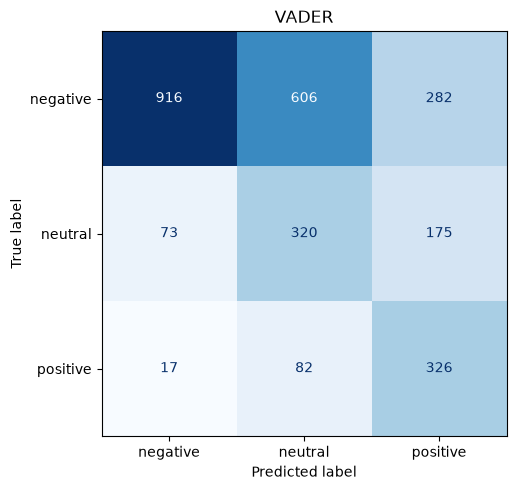

TF-IDF + LR
              precision    recall  f1-score   support

    negative       0.89      0.83      0.86      1804
     neutral       0.54      0.60      0.57       568
    positive       0.66      0.73      0.69       425

    accuracy                           0.77      2797
   macro avg       0.69      0.72      0.71      2797
weighted avg       0.78      0.77      0.77      2797



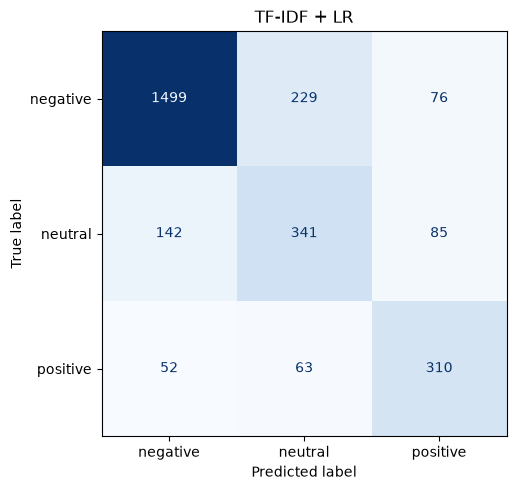

In [6]:
def make_sentiment_model(C):
    return Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=.98,
                                  max_features=35000, sublinear_tf=True)),
        ('lr', LogisticRegression(C=C, class_weight='balanced', max_iter=1200, random_state=SEED))
    ])

ml_trials = []
for C in [.5, 1., 2.]:
    candidate = make_sentiment_model(C)
    candidate.fit(sent_train.processed, sent_train.label)
    ml_trials.append({'C': C, **evaluate(sent_val.label, candidate.predict(sent_val.processed))})
ml_validation = pd.DataFrame(ml_trials).sort_values('macro_f1', ascending=False, kind='stable')
display(ml_validation)
best_C = float(ml_validation.iloc[0].C)
sent_final_train = pd.concat([sent_train, sent_val])
sent_model = make_sentiment_model(best_C).fit(sent_final_train.processed, sent_final_train.label)

lex_pred = classify_scores(lexicon_scores(sent_test.text), best_lower, best_upper)
ml_pred = sent_model.predict(sent_test.processed)
majority = sent_final_train.label.mode()[0]
sent_metrics = pd.DataFrame([
    {'method': 'Majority baseline', **evaluate(sent_test.label, np.repeat(majority, len(sent_test)))},
    {'method': 'VADER (validation thresholds)', **evaluate(sent_test.label, lex_pred)},
    {'method': 'TF-IDF + Logistic Regression', **evaluate(sent_test.label, ml_pred)}
])
display(sent_metrics)
save_table(sent_metrics, 'task1_metrics.csv')
for name, pred in [('VADER', lex_pred), ('TF-IDF + LR', ml_pred)]:
    print(name)
    print(classification_report(sent_test.label, pred, labels=SENTIMENT_LABELS, zero_division=0))
    show_confusion(sent_test.label, pred, SENTIMENT_LABELS, name)

### 1.3. Анализ ошибок

Ниже показаны **реальные ошибки на отложенной выборке**. Метки причин — подсказки по
наблюдаемым признакам, а не автоматически доказанная интерпретация сарказма.
Низкая согласованность разметки, неоднозначная ирония и эмоционально нейтральные слова
в контексте жалобы могут ограничивать оба метода.

In [7]:
error_rows = []
for method, predictions in [('VADER', lex_pred), ('TF-IDF + LR', ml_pred)]:
    errors = sent_test.assign(predicted=predictions).query('label != predicted')
    for row in errors.head(8).itertuples():
        lower = row.text.lower()
        hints = []
        if re.search(r"\b(not|no|never)\b|n't", lower): hints.append('проверить область действия отрицания')
        if any(w in lower for w in ['thanks', 'great', 'love', 'awesome']):
            hints.append('проверить иронию / смешанную тональность; возможна неоднозначность разметки')
        if not hints: hints.append('проверить контекст услуги, многозначность и потери при предобработке')
        error_rows.append({'method': method, 'text': row.text, 'true': row.label,
                           'predicted': row.predicted, 'hypothesis_to_check': '; '.join(hints)})
sentiment_errors = pd.DataFrame(error_rows)
with pd.option_context('display.max_colwidth', 180): display(sentiment_errors)
save_table(sentiment_errors, 'task1_errors.csv')

def predict_sentiment(text):
    score = float(lexicon_scores([text])[0])
    return {'text': text, 'lexicon_score': score,
        'VADER': classify_scores(np.array([score]), best_lower, best_upper)[0],
        'ML': sent_model.predict([sentiment_preprocess(text)])[0]}
display(pd.DataFrame([predict_sentiment(t) for t in [
    'I loved the friendly service!', 'My flight was cancelled and nobody helped.',
    'The flight departs at six.', 'Great, another three-hour delay.']]))

,method,text,true,predicted,hypothesis_to_check
0,VADER,@united the emails/calls over the past months about flight changes were helpful wish you would have sent them on the Cancelled Flightlation yesterday,negative,positive,"проверить контекст услуги, многозначность и потери при предобработке"
1,VADER,"@SouthwestAir I'm really craving your pretzels, please send me some.",positive,neutral,"проверить контекст услуги, многозначность и потери при предобработке"
2,VADER,@AmericanAir I did. 5 times. With 4 of those being hung up on. The other one it finally sent me to the call back notification. #FixYourStuff,negative,neutral,"проверить контекст услуги, многозначность и потери при предобработке"
3,VADER,@VirginAmerica @ladygaga @carrieunderwood Julie Andrews first but Lady Gaga wow'd me last night. Carrie? Meh.,neutral,negative,"проверить контекст услуги, многозначность и потери при предобработке"
4,VADER,@JetBlue you wanna help out? How about you reimburse the money you cause my band to lose.,negative,neutral,"проверить контекст услуги, многозначность и потери при предобработке"
5,VADER,@AmericanAir don't you guys have an email address? Just put me on the next available flight from ohare,negative,neutral,проверить область действия отрицания
6,VADER,@SouthwestAir has become like every other airline #crooked I can't believe they are taking over $500 #shouldwearmasks #shocked,negative,neutral,проверить область действия отрицания
7,VADER,"@VirginAmerica help, left expensive headphones on flight 89 IAD to LAX today. Seat 2A. No one answering L&amp;F number at LAX!",negative,neutral,проверить область действия отрицания
8,TF-IDF + LR,"@SouthwestAir I'm really craving your pretzels, please send me some.",positive,negative,"проверить контекст услуги, многозначность и потери при предобработке"
9,TF-IDF + LR,@VirginAmerica @ladygaga @carrieunderwood Julie Andrews first but Lady Gaga wow'd me last night. Carrie? Meh.,neutral,positive,"проверить контекст услуги, многозначность и потери при предобработке"


,text,lexicon_score,VADER,ML
0,I loved the friendly service!,0.8122,positive,positive
1,My flight was cancelled and nobody helped.,-0.2500,negative,negative
2,The flight departs at six.,0.0000,neutral,neutral
3,"Great, another three-hour delay.",0.4215,positive,negative


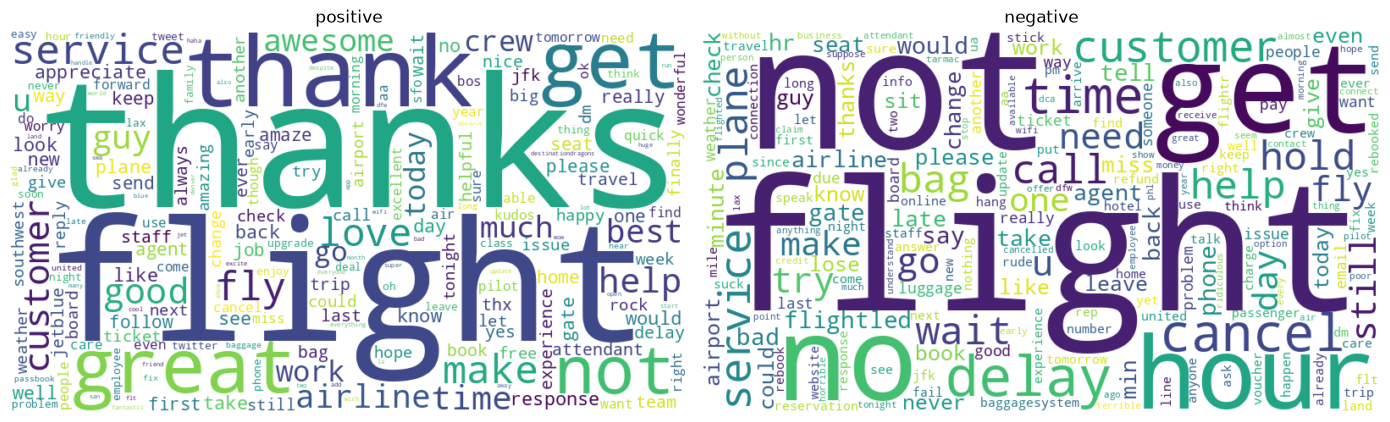

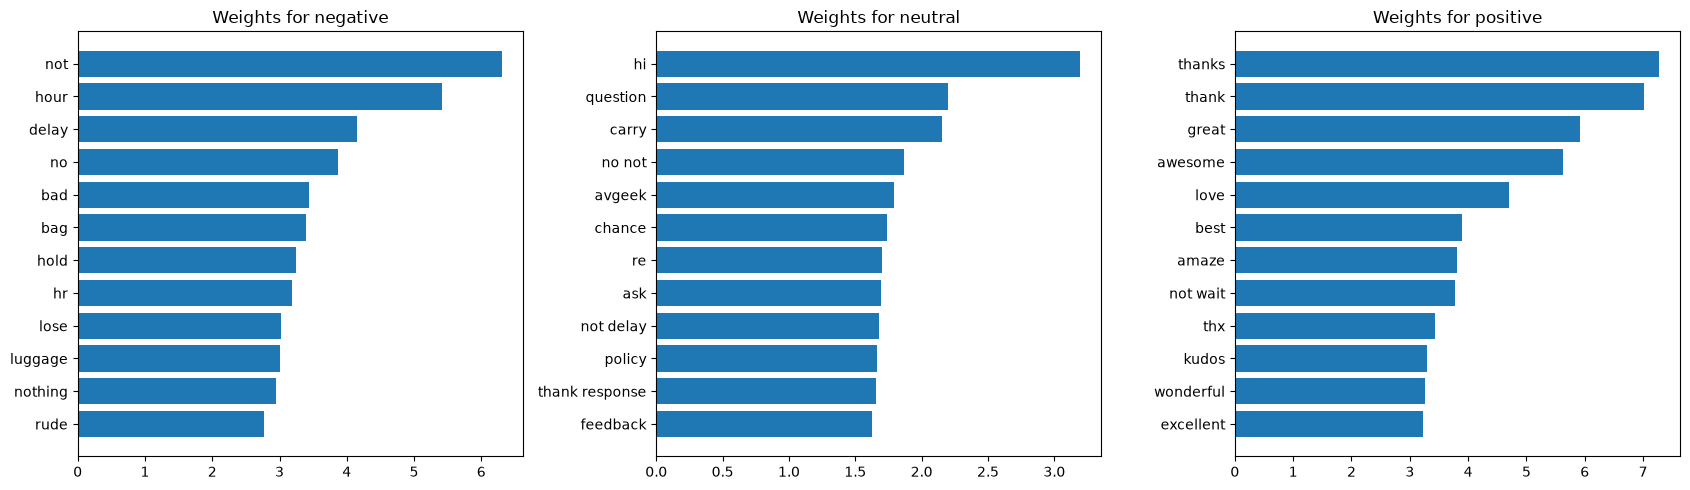

**Вывод:** на этом test лучше по macro F1 метод **TF-IDF + Logistic Regression** (0.706). Для улучшения: учитывать область отрицания, словарь авиаперевозок, контекстные модели и отдельно оценивать сарказм. Перенос на другие домены требует новой проверки.

In [8]:
# Облака слов строим по обучающим данным, не по тесту.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, label in zip(axes, ['positive', 'negative']):
    frequencies = Counter(' '.join(sent_final_train.loc[sent_final_train.label == label, 'processed']).split())
    cloud = WordCloud(width=800, height=450, background_color='white', random_state=SEED,
                      collocations=False).generate_from_frequencies(frequencies)
    ax.imshow(cloud, interpolation='bilinear'); ax.axis('off'); ax.set_title(label)
fig.tight_layout(); fig.savefig(RESULTS / 'task1_wordclouds.png', dpi=150); plt.show()

features = sent_model.named_steps['tfidf'].get_feature_names_out()
classifier = sent_model.named_steps['lr']
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
weight_rows = []
for ax, label, weights in zip(axes, classifier.classes_, classifier.coef_):
    top = np.argsort(weights)[-12:]
    ax.barh(features[top], weights[top]); ax.set_title(f'Weights for {label}')
    for j in top: weight_rows.append({'class': label, 'feature': features[j], 'weight': weights[j]})
fig.tight_layout(); fig.savefig(RESULTS / 'task1_feature_weights.png', dpi=150); plt.show()
save_table(pd.DataFrame(weight_rows), 'task1_top_features.csv')
best = sent_metrics.iloc[1:].sort_values('macro_f1', ascending=False).iloc[0]
display(Markdown(f'**Вывод:** на этом test лучше по macro F1 метод **{best.method}** '
    f'({best.macro_f1:.3f}). Для улучшения: учитывать область отрицания, словарь авиаперевозок, '
    'контекстные модели и отдельно оценивать сарказм. Перенос на другие домены требует новой проверки.'))

## Задание 2. Автоматическая суммаризация

Статьи предоставлены вместе с заданием и посвящены обнаружению музыкального плагиата.
**Для extractive части:** первые три файла, по 3 предложения из каждого и единый список из 6.
**Для advanced abstractive части:** все пять файлов.
Оригиналы сохраняем для цитирования; чистим переносы строк и артефакты извлечения PDF.
Предложения ранжируем по TF-IDF-центроиду. Для общего списка оценки вычисляются в
**одном общем пространстве TF-IDF**, поэтому веса разных документов сопоставимы.

In [9]:
EMBEDDED_ARTICLES = {
  "article1.txt": "1. Introduction\nIn recent years, music plagiarism has become a \nserious issue in the music industry. With growing use\nof the World Wide Web, the revenue loss due to\nplagiarism and pirate copies has been escalating\nexponentially. In Korea, it is estimated to be more than \n2 billion dollar (2009) [1]. The proposed music \nplagiarism detection system should be a welcome news \nto the music industry. Music often characterized by its melody, harmony, \nrhythm and timbre. Amongst these characteristics of \nmusic, melody is considered to be the most creative \nspecific and expressive element that characterizes\nmusic. With respect to melody, Korea Entertainment \nlaw society conducted a survey to find out what people \nconsidered music plagiarism to be. From the survey, \nmusic plagiarism is suspected under the following \ncases [2]:\n1. When two music have similar successive\nmelody notes, plagiarism can be suspected. 2. When two music share the unique parts of\nmelody which is rarely uses in others, plagiarism can be suspected. 3. When music has similar melody progress with \ndifferent key and instruments, plagiarism can be \nsuspected.\nWith this in mind, the music plagiarism detection \nsystem is developed in this paper. Music plagiarism \ndetection systems had been studied in the past but only \nwith MIDI as input. [3]. This system receives PCM \ndata as a query and extracts melody from it. Then, it \ncalculates the melody similarity to the music in the \ndatabase and retrieves the plagiarized music.\nThis paper is organized as follows. Section 2 shows \nwhole system to detect music plagiarism. Section 3 \ndescribes melody extraction algorithm from \npolyphonic music via harmonic model. Section 4 \nrepresents symbolic melody similarity calculation \nbased on string matching algorithm. Section 5 \ndescribes music plagiarism detecting system and \nexperiments. Finally, section 6 concludes this paper.\n2. System Overview\nThe system is composed of four modules as\nillustrated in Fig. 1: (1)Melody Extraction Module, \n(2)Melody-to-MIDI Module, (3)Similarity Calculation \nModules and (4)Common Subsequence Search \nModules. The system receives as input a polyphonic \nmusic (PCM data) and outputs information of\nplagiarized music (music title, time, etc.). In the Melody Extraction Modules, melody of the \nquery music is extracted. In the Melody-to-MIDI \nConversion Modules, the melody pitch sequence is \nconverted into a note sequence which is appropriate for \nMIDI format. In Similarity Calculation Modules, the \nsimilarity between the note sequence of the input \npolyphonic music and those of music in the database is \ncalculated. In the Common Subsequence Search \nModules, the similar section of the music in the \ndatabase is detected. Thus, the overall system can \ndetect a plagiarized music and its similar section.",
  "article2.txt": "Introduction \nRecently, the use of various types of multimedia data such as images, videos, and \naudios has shown its explosive growth, so the content-based search became of great \nimportance[12][7][13][5][4][3]. For the successful content-based search, an indexing \nscheme and a query processing scheme are the key issues to be considered. Despite of \nits great advance, audio search has been less investigated than either image or video \nsearches [8]. \nIn this paper, we address the development of a system that detects plagiarism \nbased on the similar melody searching, which is an operation that finds the melodies \nsimilar to a given query melody from a music database. Specifically, the plagiarism \ndetection system is to examine if there exist such melodies in music databases as \nbeing similar to any melodies of a composerís interest. Without realizing it, any com\u0002posers may be involved in diverse plagiarism disputes. The main purpose of this \nresearch is to help composers to avoid unnecessary plagiarism disputes by using the \nplagiarism detection system in advance. \nUnlike such previous systems as [6][8][9][10], our plagiarism detection system has \nits unique characteristics as follows: \n• A novel similarity model: it solves the problem of misjudgment by supporting \nalignment as well as shifting in the similarity model. \n• Multidimensional indexing: it makes a basic framework for fast searching by em\u0002ploying a multidimensional index built on melody features. \nMusic Plagiarism Detection Using Melody Databases 685 \n• A three-step query processing: it provides fast search ability by taking a three-step \nquery processing method, which consists of index searching, window stitching, \nand post-processing. \nThe results of performance evaluation show that our approach outperforms the se\u0002quential-scan-based one in the speed of searching up to around 31 times. \nThis paper is organized as follows. Section 2 describes a novel similarity model for \ncomputing the similarity between two different melodies. Section 3 discusses an in\u0002dexing method for efficient similar melody searching from melody databases. Section \n4 presents a three-step query processing method which employs the proposed index\u0002ing method. To show its superiority, we evaluate the performance of our system in \nSection 5. Finally, Section 6 summarizes and concludes the paper. \n2 Similarity Model \nThis section describes a similarity model to compute the similarity between two dif\u0002ferent melodies. \n2.1 Basic Model \nA melody of a music is defined as a list of snatches, i.e. as a sequence S = <(si, sLi)> \n(0<=i<n), called a melody sequence. Here, si denotes the ith tone of a melody, and sLi\ndenotes the length of the ith tone of a melody. Also, the number of tones, n, is called \nthe length of a melody sequence. For example, the following melody with a C major \nkey in four-quarters time is described as a melody sequence of length 4, i.e. <(sol, 1), \n(la, 1/2), (la, 1/2), (fa, 2)>1. \nFor comparison of any two melody sequences S = <(si, sLi)>(0<=i<n) and Q = \n<(qj, qLj)>(0<=j<m), we make the following assumptions: \n• Assumption 1: S and Q should have the same meter. In other words, two melody \nsequences of different meters are excluded for similarity searching. \n• Assumption 2: It always holds that n=m and sLi = qLj if i=j, for all (i, j)'s. Thus, \ntwo melody sequences to be compared should be of the same length, and the \nlengths of their corresponding tones should be also the same. \nFor any two melody sequences S and Q satisfying these assumptions, the similarity \nbetween S and Q is computed based on Definition 1 described below. \n\nThis paper addresses the development of a system that detects pla\u0002giarism based on similar melody searching. Similar melody searching is to find \nthe melodies similar to a given query melody from a music database. For this \npurpose, we propose a novel similarity model that supports alignment as well as \nshifting. Also, we suggest a method for indexing the features extracted from \nevery melody, and a method for processing plagiarism detection by using the \nindex. With our plagiarism detection system, composers can easily search for \nthe melodies similar to their ones from music databases. Through performance \nevaluation via a series of experiments, we show the effectiveness of our ap\u0002proach. The results reveal that our approach outperforms the sequential-scan\u0002based one in speed up to around 31 times. ",
  "article3.txt": "Music is an art whose production is very difficult. Artists work for years just to produce one song. \nEvery song produced by an artist is unique. Music plagiarism is an insult to these peoples work because the \nplagiarizer doesnt know the blood sweat and toil that goes into one song. Music plagiarism is not a new \nphenomena. It has been going for many years. However only recently with access to the internet and there by a \nhuge range of song we have come to realise just how many songs are fake. The problem with this detecting \nplagiarism is that people are biased. So they cant be wholly relied on. Another thing is that when proving \nplagiarism especially in a court of law perception of people (experts)can vary. What is needed is a way to \nquantitatively and scientifically prove plagiarism in music. This will lead to a more reliable accurate and \neffective means of detection. our project set out to be a beacon of truth to expose plagiarizers and give back \ndignity to the art that is music.\nBy using mfcc, entropy and mean energy level we have created a robust fingerprinting algorithm \n,which enables us to differentiate copies from original music.these three features have been chosen because of \ntwo major considerations.The first being that an algorithm that is extremely efficient meaning that it pin points \nplagiarism easily and without error. The second consideration is the processing time that is the time required for \nour algorithm to obtain a result.through out the project. We struggle to balance these two factors and finally we \ndecided to take these three factors. par Our comparison through taking the Euclidian distance of vector \nquantisation of features mentioned above allows us to do so. Inspite the rise of plagiarism in reason years we \nbelieve this algorithm could be usefull in playing a vital role in stamping out plagiarism. More features can be \nadded and the code can be better optimised so in the future music plagiarism becomes a thing of the past.\n\nAbstract: Music plagiarism detector is an alternative approach for music genre classification which converts \nthe audio signal into spectrograms and then extracts features from this visual representation. The idea is that \ntreating the time-frequency representation as a texture image we can extract features to build reliable music \ngenre classification systems. The proposed approach also takes into account a zoning mechanism to perform \nlocal feature extraction, which has been proved to be quite efficient. The feature include MFCC, energy, entropy \netc. In this we suggest a method for indexing the features extracted from every melody and a method for \nprocessing plagiarism detection by using the index. With our plagiarism detection system, composers can easily \nsearch for the melodies similar to their ones from music databases. Furthermore, for applications such as radio \nmonitoring, search times on the order of a few milliseconds per query are attained, even on a massive music \ndatabase.\nAbstract: Music plagiarism detector is an alternative approach for music genre classification which converts \nthe audio signal into spectrograms and then extracts features from this visual representation. The idea is that \ntreating the time-frequency representation as a texture image we can extract features to build reliable music \ngenre classification systems. The proposed approach also takes into account a zoning mechanism to perform \nlocal feature extraction, which has been proved to be quite efficient. The feature include MFCC, energy, entropy \netc. In this we suggest a method for indexing the features extracted from every melody and a method for \nprocessing plagiarism detection by using the index. With our plagiarism detection system, composers can easily \nsearch for the melodies similar to their ones from music databases. Furthermore, for applications such as radio \nmonitoring, search times on the order of a few milliseconds per query are attained, even on a massive music \ndatabase",
  "article4.txt": "Introduction\n\nAided by the internet, plagiarism is now noticeable globally ,not just across authors, but also across languages and countries. \nIn 2008 alone, 1.4 billion music tracks were sold internationally. This number has since increased to over 1.8 \nbillion. In2004, the SACEM, an organization that seeks to protect the rights of the original authors, composers \nand publishers, was able to manually check only a small percentage of registered pieces for potential copyright \nviolations. With such vast numbers of tracks to monitor, the need for automatic techniques for identification of \npotential copyright violations and detection of music-plagiarism is clear and paramount.\nWith the development of digital media technology, people are routinely exposed to music in everyday \nenvironmentscar, home, restaurant, theater and shopping mallbut are frustrated by not being able to learn more \nabout what they hear. They may, for instance, be interested in a particular piece of music and want to know its \ntitle and the name of the artist who created it. In this project Each audio file is fingerprinted, The fingerprints \nfrom the unknown sample are matched against a large set of fingerprints derived from the music database. The \ncandidate matches are subsequently evaluated for correctness of match. Music-plagiarism is the use or close \nimitation of an-other authors music without proper acknowledgement. Every year ,vast numbers of new music \ntracks are released globally, and questionable similarities exist in some sections of music tracks. \n\n\nII. Types Of Plagiarism\nA clear and precise definition of the term plagiarism is difficult to derive. However, the notion of \nintellectual property is known since ancient times. A poet named Martial called another poet kidnapper (lat. \nplagiarius), because he presented Martials poems without permission and claimed that these were his own. This \nincident is perceived as the first mention-ing of authors rights, even though an established copyright was \nunknown . Authorship became more important with the invention of letterpress printing in the late 15th century. \nIn the realm of music, it became common practice to credit the composer for his sheet music since the 16th \ncentury.\n2.1. Sampling Plagiarism\nThe term sampling describes the re-use of recorded sounds or music excerpts in another song . The \nsamples are often manipulated in pitch or tempo to fit the rhythm and tonality of the new song. It is very \ncommon to mix additional instruments to the sample, such as additional vocals or drums. The most common use \nof samples is to crop an excerpt of one or more bars and loop them. More elaborate forms of sampling include \nrearrangement and post-processing of the respective sample beyond recognition. Sampling has strongly \ninfluenced popular music culture. Thus, there exist websites4,where sampling cases are collected by a \ncommunity of music aficionados. Due to the fact that sampling is basically the use of a song in a song it is \nMusic Plagiarism Detector\nNational Conference On Discrete Mathematics & Computing (NCDMC-2017) 9 | Page\nrelated to the task of cover song detection. Cover song detection is commonly approached by chroma feature. A \nmore recent approach is presented in , where a well-known audio fingerprinting algorithm is modified in order \nto retrieve samples inside songs, based on spectral peak signatures.",
  "article5.txt": "Rhythm Plagiarism\nA prominent example for rhythm plagiarism is the so-called Amen Break. It originates from the 1969 \nFunk recording Amen Brother by The Winstons and is considered one of the most widely used drum loops in \nthe history of Rap and Electronic music. Some of such extraordinary beats are pro-tected by the law. But it is \noften difficult to judge, whether two songs share the same rhythm. There is no definition of which instrument is \nplaying the rhythm. Commonly, the drums make up the beat. But a guitar can also be a dominant rhythmical \ninstrument. In general, rhythm is formed by periodical pattern of accents in the amplitude envelopes of different \nfrequency bands. Rhythm plagiarism has been scarcely covered in the lit\u0002Erature but it is closely related to rhythm similarity estimation\nPaulus and Klapuri took the melody as a reference for rhythm\nThey transformed the melody into rhythmical strings which are easier to compare along structural dimensions. \nOthers extracted rhythmical features such as the beat spectrum or tempo in order to measure rhythmical \nsimilarity.\nMelody Plagiarism\nCopied melodies are less obvious than the previously ex-plained plagiarism types. A melodic motive is \nconsidered to be identical, even if it is transposed to another key, slowed down, sped up or interpreted with \ndifferent rhythmic accentuation. Thus, melody plagiarism is a gray area, where it is hard to discern copying \nfrom citation. However, MIR techniques are suited for inspection of such cases. In the MIR literature, a closely \nrelated task is Query-by-Humming (QbH). QbH can be used to retrieve songs from a database by letting the user \nhum or sing the respective melody. Melody plagiarism inspection can be done with basically the same approach, \nsince means to identify and evaluate melodic similarity are required. The main difference is, that QbH searches \nacross extensive databases while plagiarism detection concentrates on one single comparison, which has to be \nmore precise."
}

In [10]:
def clean_article(text):
    text = unicodedata.normalize('NFKC', text).replace('\x02', '')
    text = re.sub(r'(?<=\w)-\s*\n\s*(?=\w)', '', text)
    text = re.sub(r'^\s*(?:\d+\.\s*)?(?:Introduction|Rhythm Plagiarism)\s*$', '', text, flags=re.M)
    text = re.sub(r'\[\d+\]', '', text)
    return re.sub(r'\s+', ' ', text).strip()

documents = {}
for name, embedded in EMBEDDED_ARTICLES.items():
    local_path = Path(name)
    original = local_path.read_text(encoding='utf-8-sig') if local_path.exists() else embedded
    documents[name] = clean_article(original)
display(pd.DataFrame([{'document': name, 'words': len(text.split()),
    'sentences': len(nltk.sent_tokenize(text))} for name, text in documents.items()]))

extractive_docs = list(documents)[:3]
sentence_rows = []
for doc in extractive_docs:
    sentences = list(dict.fromkeys(s.strip() for s in nltk.sent_tokenize(documents[doc]) if len(s.split()) >= 5))
    assert len(sentences) >= 3, f'Слишком мало предложений: {doc}'
    sentence_rows.extend({'document': doc, 'position': i, 'sentence': sentence}
                         for i, sentence in enumerate(sentences))
sentence_frame = pd.DataFrame(sentence_rows)
sentence_frame['sentence_key'] = sentence_frame.sentence.map(
    lambda s: re.sub(r'[^a-z0-9]+', ' ', s.lower()).strip())
sentence_frame = sentence_frame.drop_duplicates(['document', 'sentence_key']).reset_index(drop=True)

sentence_vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), sublinear_tf=True)
sentence_X = sentence_vectorizer.fit_transform(sentence_frame.sentence)
centroid = np.asarray(sentence_X.mean(axis=0))
sentence_frame['score'] = cosine_similarity(sentence_X, centroid).ravel()

per_document = {}
for name in extractive_docs:
    top = sentence_frame[sentence_frame.document == name].nlargest(3, 'score').sort_values('position')
    per_document[name] = top.sentence.tolist()
    display(Markdown(f'### {name}: 3 ключевых предложения'))
    for i, sentence in enumerate(top.sentence, 1): print(f'{i}. {sentence}')

# Здесь именно 6 максимальных весов из общего набора, как требуется в PDF.
# Квоты по документам и подавление похожих предложений не меняют основной результат.
combined_six = (sentence_frame.sort_values('score', ascending=False, kind='stable')
    .drop_duplicates('sentence_key').head(6).reset_index(drop=True))
assert len(combined_six) == 6
display(Markdown('### Единый список: 6 предложений по убыванию веса'))
for i, row in enumerate(combined_six.itertuples(), 1):
    print(f'{i}. [{row.document}; score={row.score:.3f}] {row.sentence}')
save_table(sentence_frame, 'task2_sentence_scores.csv')
save_table(combined_six, 'task2_combined_six.csv')
(RESULTS / 'task2_extractive.json').write_text(json.dumps(per_document, ensure_ascii=False, indent=2), encoding='utf-8')

,document,words,sentences
0,article1.txt,426,33
1,article2.txt,699,36
2,article3.txt,636,33
3,article4.txt,527,30
4,article5.txt,314,18


### article1.txt: 3 ключевых предложения

1. When music has similar melody progress with different key and instruments, plagiarism can be suspected.
2. With this in mind, the music plagiarism detection system is developed in this paper.
3. Section 5 describes music plagiarism detecting system and experiments.


### article2.txt: 3 ключевых предложения

1. In this paper, we address the development of a system that detects plagiarism based on the similar melody searching, which is an operation that finds the melodies similar to a given query melody from a music database.
2. Similar melody searching is to find the melodies similar to a given query melody from a music database.
3. With our plagiarism detection system, composers can easily search for the melodies similar to their ones from music databases.


### article3.txt: 3 ключевых предложения

1. Music plagiarism is not a new phenomena.
2. In this we suggest a method for indexing the features extracted from every melody and a method for processing plagiarism detection by using the index.
3. With our plagiarism detection system, composers can easily search for the melodies similar to their ones from music databases.


### Единый список: 6 предложений по убыванию веса

1. [article2.txt; score=0.324] Similar melody searching is to find the melodies similar to a given query melody from a music database.
2. [article2.txt; score=0.321] In this paper, we address the development of a system that detects plagiarism based on the similar melody searching, which is an operation that finds the melodies similar to a given query melody from a music database.
3. [article2.txt; score=0.306] With our plagiarism detection system, composers can easily search for the melodies similar to their ones from music databases.
4. [article2.txt; score=0.274] Also, we suggest a method for indexing the features extracted from every melody, and a method for processing plagiarism detection by using the index.
5. [article3.txt; score=0.274] In this we suggest a method for indexing the features extracted from every melody and a method for processing plagiarism detection by using the index.
6. [article1.txt; score=0.261] With this in mind, the music plagiarism detection system is deve

1165

**Краткое заключение по экстрактивной части.** Общая тема первых трёх работ — поиск
заимствований в музыке путём количественного сравнения мелодий и аудиоотпечатков.
Третья статья использует MFCC, энтропию и энергию сигнала; вторая — индексирование
мелодий и трёхэтапный поиск. Автоматические методы
помогают искать сходство в больших коллекциях и уменьшают зависимость от субъективного
восприятия. Однако сходство музыкальных фрагментов само по себе не доказывает нарушение
авторского права. Ранжирование TF-IDF отражает повторяющуюся лексику, поэтому общий top-6
может сильнее представлять одну статью и содержать повторяющиеся идеи.

### 2.1. Абстрактивная сводка по пяти документам

Используем предобученную **T5-small** через Hugging Face `transformers` и
`optimum.onnxruntime`. INT8 ONNX-версия экономит память и выполняется на CPU.
[Исходная модель](https://huggingface.co/google-t5/t5-small),
[публичная ONNX-копия](https://github.com/Arfius/t5-small).
Загрузки привязаны к конкретному коммиту и проверяются SHA-256. Удалённый Python-код не исполняется.

Вместо обрезания всего корпуса до первых 512 токенов используем иерархию:
разбиваем **каждый** документ на токеновые блоки → суммируем блоки → суммируем все
промежуточные сводки до короткого общего текста. Параметры генерации ограничивают повторы.
Численные ограничения не гарантируют отсутствие фактических ошибок; результат ниже проверяем по источникам.

In [11]:
T5_CHECKSUMS = {
  "config.json": "8965dc57868800ffb28ecec5b67c1f751384995cecc800f7616987ecf7b69f71",
  "generation_config.json": "05c404488866184388896de17869dee9fc21b2fe10f77512c7aa21f51f0a6e65",
  "special_tokens_map.json": "5c87151ef0f72a99d1f766a4c418bd2a1f90aaa30a8e22fe5eca9641daebb64f",
  "spiece.model": "d60acb128cf7b7f2536e8f38a5b18a05535c9e14c7a355904270e15b0945ea86",
  "tokenizer.json": "5f0ed8ab5b8cfa9812bb73752f1d80c292e52bcf5a87a144dc9ab2d251056cbb",
  "tokenizer_config.json": "d1e7146101aa96282057f374aa9c3b260fba2109e5990edb1775d6efc70ffa3c",
  "onnx/encoder_model_quantized.onnx": "966c5cb80c2805821aa9eac5fb26dcaad44de0fee11b990ffc97500ae83044a7",
  "onnx/decoder_model_merged_quantized.onnx": "022ea05ec1c067113e03e4513c7a4c498044b316959de0a7c1dd1950e3308aa6"
}

In [12]:
import torch
import onnxruntime as ort
from transformers import AutoTokenizer
from optimum.onnxruntime import ORTModelForSeq2SeqLM

T5_BASE = 'https://raw.githubusercontent.com/Arfius/t5-small/88f269658b785fecf015c2f787a3fa9486d349f4/'
T5_DIR = DATA / 't5_small_onnx'
for filename, digest in T5_CHECKSUMS.items():
    fetch(T5_BASE + filename, T5_DIR / filename, expected_sha256=digest)

tokenizer = AutoTokenizer.from_pretrained(str(T5_DIR), local_files_only=True)
ort_options = ort.SessionOptions()
ort_options.intra_op_num_threads = min(4, os.cpu_count() or 1)
ort_options.inter_op_num_threads = 1
summary_model = ORTModelForSeq2SeqLM.from_pretrained(str(T5_DIR),
    encoder_file_name='onnx/encoder_model_quantized.onnx',
    decoder_file_name='onnx/decoder_model_merged_quantized.onnx',
    use_merged=True, use_cache=True, local_files_only=True,
    session_options=ort_options, provider='CPUExecutionProvider')

def token_count(text): return len(tokenizer.encode(text, add_special_tokens=False))

def token_chunks(text, size=430):
    ids = tokenizer.encode(text, add_special_tokens=False)
    return [tokenizer.decode(ids[i:i+size], skip_special_tokens=True)
            for i in range(0, len(ids), size)]

def summarize_chunk(text, max_new_tokens=85):
    inputs = tokenizer('summarize: ' + text, return_tensors='pt', truncation=False)
    assert inputs['input_ids'].shape[1] <= 512, 'Ошибка разбиения на токеновые блоки'
    with torch.inference_mode():
        generated = summary_model.generate(**inputs, max_new_tokens=max_new_tokens,
            min_new_tokens=20, num_beams=4, do_sample=False,
            no_repeat_ngram_size=3, repetition_penalty=1.1, early_stopping=True)
    return tokenizer.decode(generated[0], skip_special_tokens=True).strip()

document_digests = {}
chunk_log = []
for name, text in documents.items():
    chunks = token_chunks(text)
    summaries = []
    for i, chunk in enumerate(chunks):
        summary = summarize_chunk(chunk, max_new_tokens=75)
        summaries.append(summary)
        chunk_log.append({'document': name, 'chunk': i, 'tokens': token_count(chunk), 'summary': summary})
    document_digests[name] = ' '.join(summaries)
    print(name, '→', len(chunks), 'блоков обработано')

merged = ' '.join(document_digests.values())
for _ in range(8):
    if token_count(merged) <= 430: break
    smaller = ' '.join(summarize_chunk(c, max_new_tokens=65) for c in token_chunks(merged))
    if token_count(smaller) >= token_count(merged):
        raise RuntimeError('Сводка не сокращается: необходимо уменьшить max_new_tokens.')
    merged = smaller
assert token_count(merged) <= 430
abstractive_summary = summarize_chunk(merged, max_new_tokens=150)
assert abstractive_summary and len(abstractive_summary.split()) < sum(len(t.split()) for t in documents.values())
display(Markdown('### Сгенерированная абстрактивная сводка (английский)'))
print(abstractive_summary)
save_table(pd.DataFrame(chunk_log), 'task2_chunk_summaries.csv')
(RESULTS / 'task2_abstractive.txt').write_text(abstractive_summary, encoding='utf-8')

/workspace/nlp-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Token indices sequence length is longer than the specified maximum sequence length for this model (587 > 512). Running this sequence through the model will result in indexing errors


article1.txt → 2 блоков обработано


article2.txt → 3 блоков обработано


article3.txt → 2 блоков обработано


article4.txt → 2 блоков обработано


article5.txt → 1 блоков обработано


### Сгенерированная абстрактивная сводка (английский)

melody pitch sequence is converted into a note sequence. similarity between input polyphonic music and those of music in the database is calculated. break originated from the 1969 Funk recording Amen Brother by The Winstons.


224

### 2.2. Оценка полноты, связности и корректности

У статей нет эталонных аннотаций. Ниже — **авторские эталонные сводки**, подготовленные
по предоставленным материалам. Это учебные ориентиры, а не независимая экспертная разметка.
ROUGE измеряет лексическое совпадение, а не истинность или грамматическую правильность.
Извлечение оцениваем по трём исходным статьям, генерацию — по пяти: их ROUGE **нельзя
интерпретировать как прямое соревнование**, поскольку входы различаются.
Дополнительно выводим тематическое покрытие каждого документа и предложения-опоры
для каждого сгенерированного предложения. Косинусное сходство — только диагностический
прокси: оно не доказывает логическое следование и может пропустить перефразирование.

In [13]:
from rouge_score import rouge_scorer
REFERENCE_THREE = (
    'The articles address automatic detection of music plagiarism through melody similarity and audio fingerprints. '
    'Melody is a distinctive musical element, and similar melodic sequences can indicate possible copying. '
    'Content-based indexing and query processing help search large music databases. '
    'One system extracts melody from polyphonic audio and converts it to MIDI notes. '
    'Another uses MFCC, entropy and energy with vector quantization and Euclidean comparison. '
    'Quantitative comparison can support more reliable assessment than subjective listening alone, '
    'but detecting similarity does not by itself establish legal plagiarism.')
REFERENCE_FIVE = (
    'Music plagiarism detection requires scalable methods to compare musical works. '
    'The documents focus on melody similarity, content-based retrieval and quantitative analysis '
    'to support human judgments about possible copying. '
    'Digital music collections create a need for efficient indexing and automatic identification. '
    'Methods include PCM-to-MIDI melody extraction, alignment and shifting, '
    'multidimensional indexing, and fingerprints using MFCC, entropy and energy. '
    'Sampling can reuse and transform recorded excerpts, requiring audio matching. '
    'Rhythm is another relevant dimension; the Amen Break illustrates widely reused drum patterns. '
    'Rhythmic similarity involves temporal patterns and amplitude envelopes and is less studied than melody. '
    'Automatic similarity scores assist investigation but cannot alone determine copyright infringement.')
extractive_text = ' '.join(combined_six.sentence)
scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)
quality_rows = []
for method, summary, reference, names in [
    ('Extractive (3 documents)', extractive_text, REFERENCE_THREE, extractive_docs),
    ('Abstractive (5 documents)', abstractive_summary, REFERENCE_FIVE, list(documents))]:
    scores = scorer.score(reference, summary)
    quality_rows.append({'method': method, 'words': len(summary.split()),
        'compression_ratio': len(summary.split()) / sum(len(documents[n].split()) for n in names),
        **{f'{k}_F1': v.fmeasure for k, v in scores.items()}})
quality = pd.DataFrame(quality_rows)
display(quality); save_table(quality, 'task2_quality_metrics.csv')

coverage_rows = []
for method, summary in [('extractive_3_docs', extractive_text), ('abstractive_5_docs', abstractive_summary)]:
    names = extractive_docs if method.startswith('extractive') else list(documents)
    vec = TfidfVectorizer(stop_words='english')
    matrix = vec.fit_transform([documents[n] for n in names] + [summary])
    similarities = cosine_similarity(matrix[:-1], matrix[-1]).ravel()
    coverage_rows.extend({'method': method, 'document': n, 'lexical_coverage_proxy': float(v)}
                         for n, v in zip(names, similarities))
coverage = pd.DataFrame(coverage_rows)
display(coverage); save_table(coverage, 'task2_document_coverage.csv')

source_sentences = [(name, sentence) for name, text in documents.items()
                    for sentence in nltk.sent_tokenize(text) if len(sentence.split()) >= 5]
generated_sentences = nltk.sent_tokenize(abstractive_summary)
ground_vec = TfidfVectorizer(stop_words='english').fit(
    [s for _, s in source_sentences] + generated_sentences)
source_X = ground_vec.transform([s for _, s in source_sentences])
support_rows = []
for sentence in generated_sentences:
    similarity = cosine_similarity(ground_vec.transform([sentence]), source_X).ravel()
    best = int(similarity.argmax())
    support_rows.append({'generated': sentence, 'closest_source': source_sentences[best][0],
        'source_sentence': source_sentences[best][1], 'similarity_proxy': float(similarity[best])})
support = pd.DataFrame(support_rows)
with pd.option_context('display.max_colwidth', 220): display(support)
save_table(support, 'task2_factual_support_review.csv')

,method,words,compression_ratio,rouge1_F1,rouge2_F1,rougeL_F1
0,Extractive (3 documents),137,0.077797,0.315315,0.036364,0.189189
1,Abstractive (5 documents),35,0.013451,0.181818,0.000000,0.097902


,method,document,lexical_coverage_proxy
0,extractive_3_docs,article1.txt,0.427658
1,extractive_3_docs,article2.txt,0.598452
2,extractive_3_docs,article3.txt,0.404769
3,abstractive_5_docs,article1.txt,0.320625
4,abstractive_5_docs,article2.txt,0.150244
5,abstractive_5_docs,article3.txt,0.085558
6,abstractive_5_docs,article4.txt,0.087365
7,abstractive_5_docs,article5.txt,0.164455


,generated,closest_source,source_sentence,similarity_proxy
0,melody pitch sequence is converted into a note sequence.,article1.txt,"In the Melody-to-MIDI Conversion Modules, the melody pitch sequence is converted into a note sequence which is appropriate for MIDI format.",0.661924
1,similarity between input polyphonic music and those of music in the database is calculated.,article1.txt,"In Similarity Calculation Modules, the similarity between the note sequence of the input polyphonic music and those of music in the database is calculated.",0.771004
2,break originated from the 1969 Funk recording Amen Brother by The Winstons.,article5.txt,It originates from the 1969 Funk recording Amen Brother by The Winstons and is considered one of the most widely used drum loops in the history of Rap and Electronic music.,0.518498


**Интерпретация качества.**

**Разбор фактически полученной T5-сводки.** При проверенном запуске T5 оставила конвертацию
мелодии в ноты, вычисление сходства и историю Amen Break. Она пропустила MFCC/энтропию/энергию
из статьи 3, индексирование из статьи 2 и сэмплирование из статьи 4. Слово `break` потеряло
имя `Amen`, а строчные буквы в начале предложений ухудшили оформление. Поэтому краткость
модели достигнута ценой неполноты: такую сводку нельзя считать удовлетворяющей всем
критериям без редакторской проверки. Опорные предложения подтверждают сохранённые факты,
но не устраняют перечисленные пропуски. Ниже дана отдельная авторская редактура.

* **Полнота:** top-6 сохраняет наиболее весомые предложения, но ограниченный объём и
  отсутствие квот могут исключить отдельные идеи. При генерации все пять файлов проходят
  обработку, однако часть деталей может потеряться на каждом этапе сжатия. Таблица покрытия
  помогает заметить слабое представление статьи, но не заменяет содержательную проверку.
* **Связность:** извлечённые предложения грамматически исходные, но переходы между ними
  могут быть резкими; сортировка общего списка по весам дополнительно нарушает исходный порядок.
  T5 генерирует связный текст, но повторы, обрывки и неверные местоименные ссылки возможны.
* **Корректность:** экстрактивный метод не добавляет новые утверждения, но может исказить смысл
  отрывом от контекста. T5 способен галлюцинировать и смешивать детали разных статей.
  Для проверки используйте таблицу `generated → source_sentence`: отдельно проверяйте имена,
  числа, причинные утверждения и юридические выводы. Высокий ROUGE не является такой проверкой.

**Улучшения:** TextRank/MMR для разнообразия, сохранение порядка предложений в конечном
резюме, тематические квоты, более сильная summarization-модель, независимые экспертные
эталоны и ручная проверка фактов. T5-small INT8 выбран ради воспроизводимости на обычном CPU;
это учебная базовая модель, качество которой ограничено.

### Итоговая вычитанная аннотация по пяти статьям

Это **авторская редактура по исходникам**, а не автоматически сгенерированный результат T5.
Она исправляет неполноту базовой модели и служит примером качественной абстрактивной сводки:

> The five documents examine automatic methods for investigating music plagiarism in large
> digital collections. Melody-based systems extract pitch sequences from polyphonic audio,
> convert them into symbolic notes, and compare similar passages. Alignment, shifting,
> multidimensional indexing and staged query processing make melody retrieval more efficient.
> Audio fingerprinting offers another approach, using features such as MFCCs, entropy and energy.
> The texts also discuss reused samples, spectral signatures and the difficulty of distinguishing
> musical borrowing from copying. Rhythm comparison involves recurring accents and features
> such as tempo or beat spectra; the Amen Break illustrates the extensive reuse of a drum pattern.
> These methods provide quantitative evidence of similarity, but their outputs still require
> contextual interpretation and do not by themselves establish copyright infringement.

Сводка короче корпуса, связывает пять источников, не приписывает алгоритмам безошибочность
и отделяет сходство от юридического вывода. Числа из введений и перечни разделов исключены
как второстепенные. Для улучшения полностью автоматического варианта нужна более сильная
модель и проверка тематического покрытия после генерации.

## Задание 3. Упоминания в текстах песен

**Источник:** [etarakci/music-genre-prediction](https://github.com/etarakci/music-genre-prediction),
`data/genre_lyrics_data.csv`: английские тексты из AZLyrics, жанровые метки из Spotify;
происхождение описано в README источника. Данные уже частично очищены создателями корпуса.
Загружаем публичную CSV-копию без Kaggle-токена. Авторские права на тексты сохраняются
за правообладателями; здесь выводим агрегаты, а не полные тексты песен.

Используем **country, blues, folk, hip-hop**, по 10 уникальных песен с seed=42.
Проверяем наличие жанров и достаточность данных; не подменяем песни синтетическими примерами.
Жанры могут пересекаться по смыслу, но одинаковые нормализованные тексты в выборке исключаются.
В исходной CSV нет названий/исполнителей — сохраняем идентификатор строки и хеш текста.

,available_songs
genre,
country,290
blues,244
dance,231
alt-rock,216
acoustic,214
death-metal,195
j-dance,168
folk,162
singer-songwriter,159


,genre,word,count
0,country,know,52
1,country,im,31
2,country,get,24
3,country,little,19
4,country,make,15
5,country,blow,14
6,country,gonna,14
7,country,country,14
8,country,bit,14
9,country,day,13


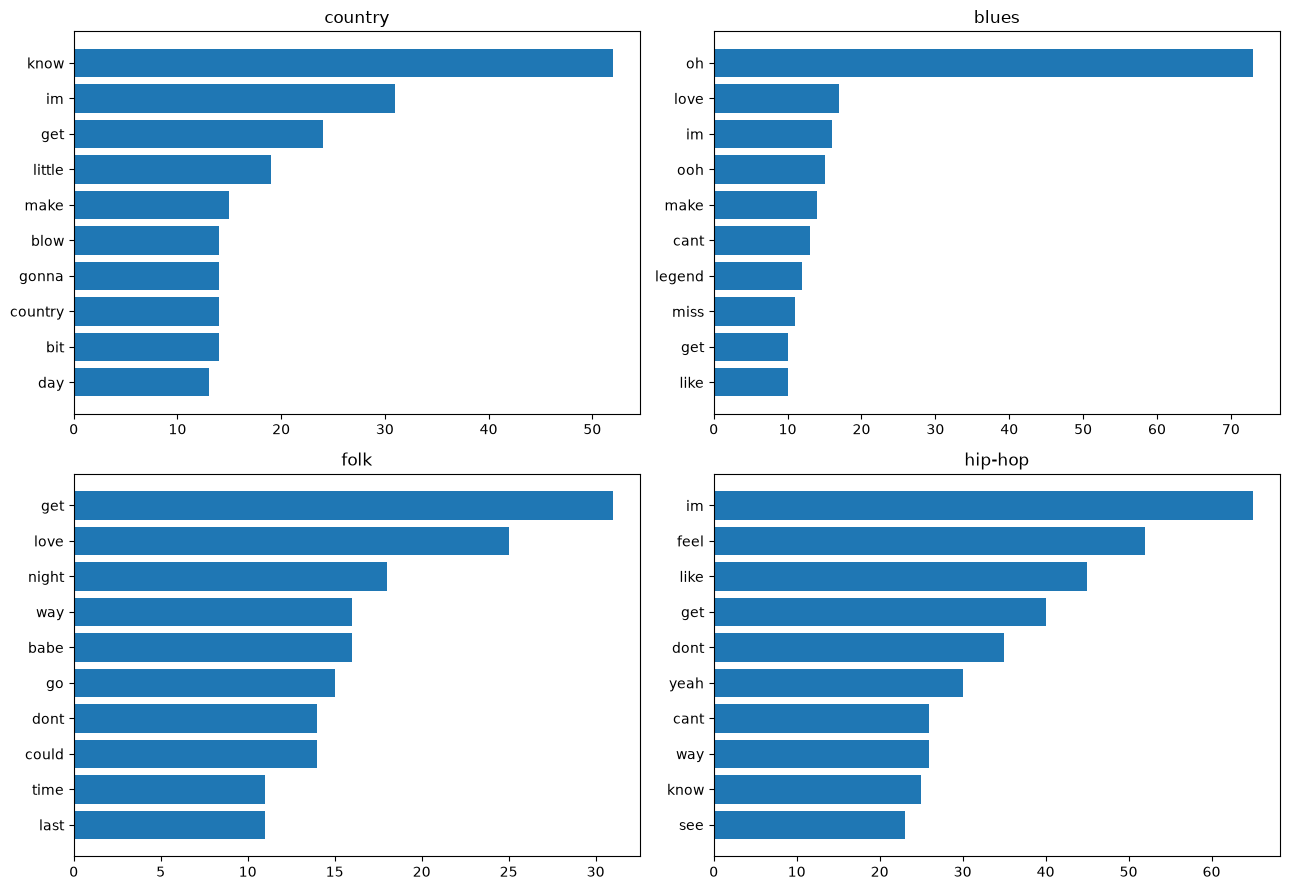

In [14]:
LYRICS_URL = ('https://raw.githubusercontent.com/etarakci/music-genre-prediction/'
    'cd007c16892ff98b40f8df1e33d26e3c8cf80127/data/genre_lyrics_data.csv')
lyrics_all = pd.read_csv(fetch(LYRICS_URL, DATA / 'genre_lyrics_data.csv'))
lyrics_all = lyrics_all.rename(columns={'genre_name': 'genre', 'lyrics_cleaned': 'lyrics'})
lyrics_all['source_row'] = np.arange(len(lyrics_all))
lyrics_all = lyrics_all.dropna(subset=['genre', 'lyrics']).copy()
lyrics_all['canonical'] = lyrics_all.lyrics.map(lambda t: re.sub(r'[^a-z]+', ' ', str(t).lower()).strip())
lyrics_all = lyrics_all[lyrics_all.canonical.str.split().str.len() >= 30].drop_duplicates('canonical')
display(lyrics_all.genre.value_counts().head(20).to_frame('available_songs'))
GENRES = ['country', 'blues', 'folk', 'hip-hop']
missing = [g for g in GENRES if (lyrics_all.genre == g).sum() < 10]
assert not missing, f'Не хватает 10 уникальных песен в жанрах {missing}. Доступные: {lyrics_all.genre.unique()}'
lyrics_sample = pd.concat([lyrics_all[lyrics_all.genre == g].sample(10, random_state=SEED)
                          for g in GENRES], ignore_index=True)
lyrics_sample['tokens'] = lyrics_sample.lyrics.map(lambda t: english_tokens(t, keep_negations=False))
lyrics_sample['text_sha256'] = lyrics_sample.canonical.map(lambda t: hashlib.sha256(t.encode()).hexdigest())
assert len(lyrics_sample) == 40 and lyrics_sample.text_sha256.nunique() == 40
assert (lyrics_sample.groupby('genre').size() == 10).all()
save_table(lyrics_sample[['source_row', 'genre', 'text_sha256']], 'task3_selected_songs.csv')
genre_counts = {genre: Counter(w for words in lyrics_sample.loc[lyrics_sample.genre == genre, 'tokens']
                               for w in words) for genre in GENRES}
top10 = pd.DataFrame([{'genre': genre, 'word': word, 'count': count}
    for genre, counts in genre_counts.items() for word, count in counts.most_common(10)])
display(top10); save_table(top10, 'task3_top10.csv')
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, genre in zip(axes.flat, GENRES):
    top = genre_counts[genre].most_common(10)[::-1]
    ax.barh([w for w, _ in top], [c for _, c in top]); ax.set_title(genre)
fig.tight_layout(); fig.savefig(RESULTS / 'task3_top10.png', dpi=150); plt.show()

,genre,category,word,count,per_1000_tokens
48,blues,body_parts,eye,8,10.075567
55,blues,body_parts,heart,3,3.778338
46,blues,body_parts,bone,1,1.259446
52,blues,body_parts,hair,1,1.259446
54,blues,body_parts,head,1,1.259446
36,blues,time_of_day,morning,3,3.778338
32,blues,time_of_day,day,2,2.518892
34,blues,time_of_day,evening,1,1.259446
37,blues,time_of_day,night,1,1.259446
25,country,body_parts,heart,7,5.409583


,genre,category,count,per_1000_tokens
0,blues,body_parts,14,17.632242
1,blues,seasons,0,0.000000
2,blues,time_of_day,7,8.816121
3,country,body_parts,16,12.364760
4,country,seasons,2,1.545595
5,country,time_of_day,15,11.591963
6,folk,body_parts,33,29.837251
7,folk,seasons,7,6.329114
8,folk,time_of_day,23,20.795660
9,hip-hop,body_parts,15,6.877579


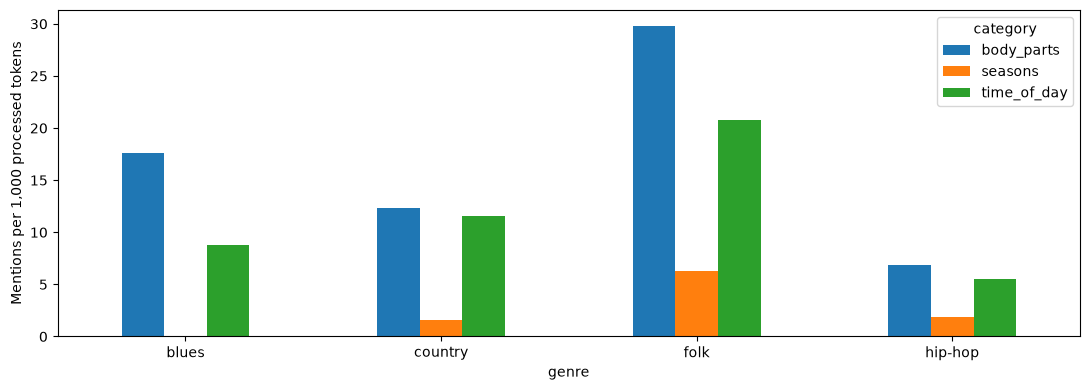

### Редкие слова отдельно для каждого жанра (1–3 вхождения)

,number_of_rare_words
genre,
blues,245
country,372
folk,370
hip-hop,629


,genre,word,count
0,country,abandon,1
1,country,across,2
2,country,agree,1
3,country,alligator,2
4,country,almost,1
5,country,alone,1
6,country,along,3
7,country,always,1
8,country,another,3
9,country,anyone,1


### Слова, встречающиеся во всех 4 жанрах и в каждом не более 3 раз

,word,country,blues,folk,hip-hop
0,alone,1,3,1,1
1,everything,1,1,2,1
2,fight,1,1,1,2
3,grow,2,1,1,1
4,guess,1,2,1,3
5,live,2,1,2,3
6,morning,1,3,1,3
7,much,1,1,3,2
8,old,1,1,2,2
9,people,1,1,1,3


**Вывод по выборке:**

blues: наиболее частая из заданных категорий — body_parts, 17.6 упоминаний на 1000 обработанных токенов.
country: наиболее частая из заданных категорий — body_parts, 12.4 упоминаний на 1000 обработанных токенов.
folk: наиболее частая из заданных категорий — body_parts, 29.8 упоминаний на 1000 обработанных токенов.
hip-hop: наиболее частая из заданных категорий — body_parts, 6.9 упоминаний на 1000 обработанных токенов.


In [15]:
# Категории заданы в лемматизированном виде: eyes -> eye, hands -> hand.
CATEGORIES = {
    'time_of_day': {'morning', 'day', 'afternoon', 'evening', 'night', 'midnight', 'dawn', 'dusk'},
    'seasons': {'winter', 'spring', 'summer', 'autumn', 'fall'},
    'body_parts': {'eye', 'heart', 'hand', 'head', 'face', 'arm', 'leg', 'foot', 'hair',
                   'mouth', 'lip', 'ear', 'finger', 'skin', 'body', 'blood', 'bone'}
}
category_rows = []
for genre, counts in genre_counts.items():
    total = sum(counts.values())
    for category, dictionary in CATEGORIES.items():
        for word in sorted(dictionary):
            n = counts[word]
            category_rows.append({'genre': genre, 'category': category, 'word': word,
                                  'count': n, 'per_1000_tokens': 1000*n/total})
category_words = pd.DataFrame(category_rows)
display(category_words.query('count > 0').sort_values(['genre', 'category', 'count'], ascending=[True, True, False]))
category_totals = category_words.groupby(['genre', 'category'])[['count', 'per_1000_tokens']].sum().reset_index()
display(category_totals)
category_totals.pivot(index='genre', columns='category', values='per_1000_tokens').plot.bar(figsize=(11, 4))
plt.ylabel('Mentions per 1,000 processed tokens'); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(RESULTS / 'task3_categories.png', dpi=150); plt.show()
save_table(category_words, 'task3_category_words.csv')
save_table(category_totals, 'task3_category_totals.csv')

# В PDF есть две формулировки редкости. Показываем обе явно.
rare_per_genre = pd.DataFrame([{'genre': genre, 'word': word, 'count': count}
    for genre, counts in genre_counts.items() for word, count in sorted(counts.items()) if 1 <= count <= 3])
display(Markdown('### Редкие слова отдельно для каждого жанра (1–3 вхождения)'))
display(rare_per_genre.groupby('genre').size().to_frame('number_of_rare_words'))
display(rare_per_genre.groupby('genre', sort=False).head(15))
save_table(rare_per_genre, 'task3_rare_per_genre_FULL.csv')

shared_vocabulary = set.intersection(*(set(c) for c in genre_counts.values()))
shared_rare_words = sorted(w for w in shared_vocabulary if all(1 <= genre_counts[g][w] <= 3 for g in GENRES))
shared_rare = pd.DataFrame([{'word': w, **{g: genre_counts[g][w] for g in GENRES}} for w in shared_rare_words],
                         columns=['word'] + GENRES)
display(Markdown('### Слова, встречающиеся во всех 4 жанрах и в каждом не более 3 раз'))
display(shared_rare)
if shared_rare.empty: print('Таких слов в выбранных 40 песнях нет — это допустимый результат.')
save_table(shared_rare, 'task3_shared_rare_FULL.csv')

top_categories = category_totals.loc[category_totals.groupby('genre').per_1000_tokens.idxmax()]
display(Markdown('**Вывод по выборке:**'))
for row in top_categories.itertuples():
    print(f'{row.genre}: наиболее частая из заданных категорий — {row.category}, '
          f'{row.per_1000_tokens:.1f} упоминаний на 1000 обработанных токенов.')

**Ограничения:** по 10 песен недостаточно, чтобы обобщать выводы на весь жанр.
Повторы припева увеличивают частоты, поэтому нормируем также на 1000 токенов.
`heart` может быть метафорой, `fall` — глаголом, `spring` — не временем года:
словарный подсчёт измеряет упоминания слов, а не гарантированно их смысл.
Для улучшения нужны контекстное снятие многозначности, больший стратифицированный корпус
и учёт исполнителя/эпохи; этих полей в выбранной CSV нет.

## Задание 4. Определение языка

**Корпус:** [WiLI-2018](https://zenodo.org/records/841984), Wikipedia language identification,
[статья](https://arxiv.org/abs/1801.07779). Для автоматической загрузки используем
[публичное зеркало исходных файлов](https://github.com/alianoroozi/Language-Identification/tree/master/wili-2018)
с закреплённым коммитом. Языки: **английский, русский, французский, немецкий, испанский,
португальский**. Испанский и португальский — близкая пара.

Объединяем исходные train/test, затем заново строим требуемое стратифицированное **80/20**.
Удаляем дубликаты после Unicode-нормализации и после агрессивной очистки; конфликтующие
метки исключаем. Берём **800 уникальных примеров на язык**. В WiLI строки часто содержат
абзацы, а не ровно одно предложение; поэтому ниже дополнительно проверяем короткие входы.

**Проверяемая матрица экспериментов:** 2 очистки × 2 типа TF-IDF × 2 классификатора = 8 моделей.
Гиперпараметры фиксированы заранее, по test их не подбираем. Лучший результат таблицы —
описание данного теста, а не оценка выбора модели на независимом третьем наборе.

In [16]:
WILI_BASE = ('https://raw.githubusercontent.com/alianoroozi/Language-Identification/'
             '9338c39f7dba99785bbedc7309013091f22d838c/wili-2018/')
LANGUAGES = {'eng': 'English', 'rus': 'Russian', 'fra': 'French',
             'deu': 'German', 'spa': 'Spanish', 'por': 'Portuguese'}
ISO3_TO_ISO2 = {'eng': 'en', 'rus': 'ru', 'fra': 'fr', 'deu': 'de', 'spa': 'es', 'por': 'pt'}

def minimal_clean(text):
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFKC', str(text))).strip()

def aggressive_clean(text):
    # Сохраняем ВСЕ Unicode-буквы: ә, қ, ғ, ñ, ü, é и т.д. не исчезают.
    return re.sub(r'\s+', ' ', ''.join(ch if ch.isalpha() or ch.isspace() else ' '
                                      for ch in minimal_clean(text).lower())).strip()

assert aggressive_clean('Ә Қ Ғ Ң Ө Ү é ñ 123 !') == 'ә қ ғ ң ө ү é ñ'
wili_rows = []
for split in ['train', 'test']:
    x_path = fetch(WILI_BASE + f'x_{split}.txt', DATA / 'wili' / f'x_{split}.txt')
    y_path = fetch(WILI_BASE + f'y_{split}.txt', DATA / 'wili' / f'y_{split}.txt')
    from itertools import zip_longest
    with open(x_path, encoding='utf-8-sig') as xf, open(y_path, encoding='utf-8-sig') as yf:
        for line_no, (text, label) in enumerate(zip_longest(xf, yf)):
            assert text is not None and label is not None, 'Число строк текстов и меток различается'
            label = label.strip()
            if label in LANGUAGES:
                wili_rows.append({'text': minimal_clean(text), 'label': LANGUAGES[label],
                                  'iso3': label, 'source_split': split, 'source_line': line_no})
wili = pd.DataFrame(wili_rows)
wili['canonical'] = wili.text.map(aggressive_clean)
wili = wili[wili.canonical.str.split().str.len() >= 3]
label_counts = wili.groupby('canonical').label.nunique()
wili = wili[~wili.canonical.isin(label_counts[label_counts > 1].index)].drop_duplicates('canonical')
display(wili.label.value_counts().to_frame('available_unique_examples'))
N_PER_LANGUAGE = 800
assert wili.label.value_counts().min() >= N_PER_LANGUAGE
language_data = pd.concat([group.sample(N_PER_LANGUAGE, random_state=SEED)
                          for _, group in wili.groupby('label')], ignore_index=True)
lang_train, lang_test = train_test_split(language_data, test_size=.2, random_state=SEED,
                                       stratify=language_data.label)
assert set(lang_train.canonical).isdisjoint(lang_test.canonical)
assert set(lang_train.text).isdisjoint(lang_test.text)
assert len(lang_train) == 3840 and len(lang_test) == 960
display(pd.concat({'train': lang_train.label.value_counts(), 'test': lang_test.label.value_counts()}, axis=1))
save_table(language_data.drop(columns='canonical'), 'task4_selected_data.csv')

,available_unique_examples
label,
English,1000
German,1000
Russian,999
Portuguese,997
Spanish,996
French,990


,train,test
label,,
Spanish,640,160
German,640,160
French,640,160
Russian,640,160
Portuguese,640,160
English,640,160


In [17]:
LANG_LABELS = sorted(LANGUAGES.values())
language_models, language_predictions, language_scores = {}, {}, []
for cleaning, preprocessor in [('minimal', minimal_clean), ('aggressive', aggressive_clean)]:
    for feature_type in ['char', 'word']:
        for model_type in ['NB', 'LR']:
            vectorizer = TfidfVectorizer(preprocessor=preprocessor, lowercase=False,
                analyzer=feature_type, ngram_range=(1, 3) if feature_type == 'char' else (1, 1),
                min_df=2, max_features=60000, sublinear_tf=True)
            estimator = (MultinomialNB(alpha=.1) if model_type == 'NB' else
                         LogisticRegression(C=3, max_iter=1000, random_state=SEED))
            model = Pipeline([('tfidf', vectorizer), ('classifier', estimator)])
            model.fit(lang_train.text, lang_train.label)
            name = f'{cleaning}/{feature_type}/{model_type}'
            predicted = model.predict(lang_test.text)
            language_models[name] = model
            language_predictions[name] = predicted
            language_scores.append({'model': name, 'cleaning': cleaning, 'features': feature_type,
                                    'classifier': model_type, **evaluate(lang_test.label, predicted)})
            print(name, 'готово', flush=True)
language_metrics = pd.DataFrame(language_scores)
display(language_metrics.sort_values('macro_f1', ascending=False))
save_table(language_metrics, 'task4_classical_metrics.csv')

minimal/char/NB готово


minimal/char/LR готово


minimal/word/NB готово


minimal/word/LR готово


aggressive/char/NB готово


aggressive/char/LR готово


aggressive/word/NB готово


aggressive/word/LR готово


,model,cleaning,features,classifier,accuracy,macro_f1
2,minimal/word/NB,minimal,word,NB,0.990625,0.990715
1,minimal/char/LR,minimal,char,LR,0.990625,0.990687
7,aggressive/word/LR,aggressive,word,LR,0.989583,0.989656
5,aggressive/char/LR,aggressive,char,LR,0.988542,0.988644
3,minimal/word/LR,minimal,word,LR,0.988542,0.988629
6,aggressive/word/NB,aggressive,word,NB,0.987500,0.987616
0,minimal/char/NB,minimal,char,NB,0.980208,0.980476
4,aggressive/char/NB,aggressive,char,NB,0.978125,0.978482


### 4.1. Предобученный baseline fastText lid.176

[Официальная модель Meta](https://fasttext.cc/docs/en/language-identification.html),
сжатый файл `lid.176.ftz` (~0.94 MB), 176 языков. При недоступности официального сервера
используется [публичная копия](https://github.com/sherozshaikh/pdflangdetect), **проверяемая
по тому же SHA-256**. Метки baseline **не ограничиваются** выбранными шестью языками:
предсказание другого языка считается ошибкой, а не принудительно заменяется.

fastText уже обучался на внешних данных, включая Wikipedia. Поэтому возможное пересечение
источников с WiLI — ограничение честности сравнения; он не обучается на нашем train.
Вероятности baseline — оценки модели, а не гарантированно откалиброванная уверенность.
Macro F1 усредняется по шести истинным целевым языкам для всех методов одинаково.

In [18]:
import fasttext
FASTTEXT_SHA256 = '8f3472cfe8738a7b6099e8e999c3cbfae0dcd15696aac7d7738a8039db603e83'
FASTTEXT_URLS = [
    'https://dl.fbaipublicfiles.com/fasttext/supervised-models/lid.176.ftz',
    ('https://raw.githubusercontent.com/sherozshaikh/pdflangdetect/'
     '068fe2f45464a8124617dfe1b58fad8cf82443b4/src/pdflangdetect/_data/lid.176.ftz')]
ft_path = None
for url in FASTTEXT_URLS:
    try:
        ft_path = fetch(url, DATA / 'lid.176.ftz', expected_sha256=FASTTEXT_SHA256)
        break
    except (requests.RequestException, ValueError) as exc:
        print(f'Источник недоступен: {type(exc).__name__}. Пробуем проверенное зеркало.')
if ft_path is None: raise RuntimeError('Не удалось загрузить fastText. Нужен доступ к одному из источников.')
ft_model = fasttext.load_model(str(ft_path))
iso2_names = {ISO3_TO_ISO2[k]: v for k, v in LANGUAGES.items()}

def fasttext_predict(texts, with_confidence=False):
    labels, confidences = [], []
    for text in texts:
        safe = minimal_clean(text).replace('\n', ' ')
        label, probability = ft_model.predict(safe, k=1)
        iso2 = label[0].removeprefix('__label__')
        labels.append(iso2_names.get(iso2, f'other:{iso2}'))
        confidences.append(float(probability[0]))
    return (np.array(labels), np.array(confidences)) if with_confidence else np.array(labels)

ft_pred = fasttext_predict(lang_test.text)
language_predictions['fastText lid.176'] = ft_pred
all_language_metrics = pd.concat([language_metrics, pd.DataFrame([
    {'model': 'fastText lid.176', 'cleaning': 'minimal', 'features': 'pretrained',
     'classifier': 'fastText', **evaluate(lang_test.label, ft_pred)}])], ignore_index=True)
display(all_language_metrics.sort_values('macro_f1', ascending=False))
save_table(all_language_metrics, 'task4_all_metrics.csv')

,model,cleaning,features,classifier,accuracy,macro_f1
2,minimal/word/NB,minimal,word,NB,0.990625,0.990715
1,minimal/char/LR,minimal,char,LR,0.990625,0.990687
7,aggressive/word/LR,aggressive,word,LR,0.989583,0.989656
5,aggressive/char/LR,aggressive,char,LR,0.988542,0.988644
3,minimal/word/LR,minimal,word,LR,0.988542,0.988629
6,aggressive/word/NB,aggressive,word,NB,0.987500,0.987616
8,fastText lid.176,minimal,pretrained,fastText,0.981250,0.981958
0,minimal/char/NB,minimal,char,NB,0.980208,0.980476
4,aggressive/char/NB,aggressive,char,NB,0.978125,0.978482


cleaning             aggressive   minimal  aggressive_minus_minimal
features classifier                                                
char     LR            0.988644  0.990687                 -0.002044
         NB            0.978482  0.980476                 -0.001994
word     LR            0.989656  0.988629                  0.001027
         NB            0.987616  0.990715                 -0.003099

char/LR: minimal лучше, Δ macro F1 = -0.0020
char/NB: minimal лучше, Δ macro F1 = -0.0020
word/LR: aggressive лучше, Δ macro F1 = +0.0010
word/NB: minimal лучше, Δ macro F1 = -0.0031
              precision    recall  f1-score   support

     English       0.95      1.00      0.98       160
      French       1.00      0.99      1.00       160
      German       1.00      1.00      1.00       160
  Portuguese       0.99      0.97      0.98       160
     Russian       1.00      0.99      0.99       160
     Spanish       1.00      0.99      0.99       160

    accuracy                           0.99       960
   macro avg       0.99      0.99      0.99       960
weighted avg       0.99      0.99      0.99       960



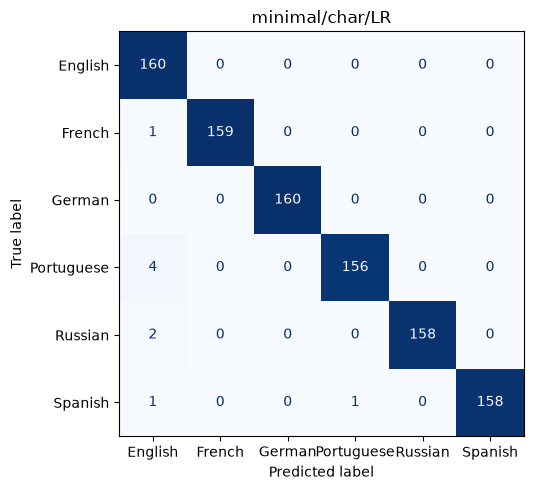

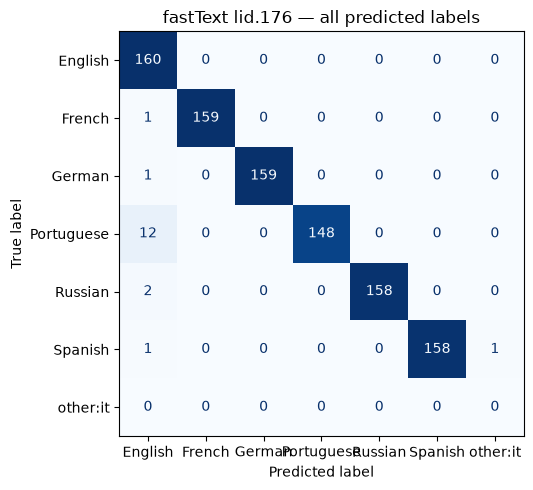

,label,predicted,errors
1,Portuguese,English,4
2,Russian,English,2
0,French,English,1



Portuguese → English: 4 ошибок. Пример: Gillison, Douglas (1962). Australia in the War of 1939–1945: Series Three (Air) Volume I – Royal Australian Air Force 1939–1942 (em inglês). Camberra: Australian War Memorial. OCLC 2000369
Проверить цитаты на другом языке, имена, общую лексику и возможную ошибку разметки Wikipedia.

Russian → English: 2 ошибок. Пример: Thomson, Harry C. ; Mayo, Lida. The Ordnance Department: Procurement and Supply. (англ.) — Washington, D.C.: U.S. Dept. of the Army, Office of the Chief of Military History, 1960. — 504 p.
Проверить цитаты на другом языке, имена, общую лексику и возможную ошибку разметки Wikipedia.

French → English: 1 ошибок. Пример: (en) T. Robert S. Broughton (The American Philological Association), The Magistrates of the Roman Republic : Volume I, 509 B.C. - 100 B.C., New York, Press of Case Western Reserve University (Leveland, Ohio), coll. « Philological Monographs, number XV, volume I », 1951, 578 p.
Проверить цитаты на другом языке, имена,

In [19]:
# Интерпретация эксперимента с предобработкой без заранее придуманного победителя.
cleaning_comparison = language_metrics.pivot(index=['features', 'classifier'],
                                            columns='cleaning', values='macro_f1')
cleaning_comparison['aggressive_minus_minimal'] = cleaning_comparison.aggressive - cleaning_comparison.minimal
display(cleaning_comparison)
for (feature_type, classifier), row in cleaning_comparison.iterrows():
    delta = row.aggressive_minus_minimal
    outcome = 'одинаковы' if abs(delta) < 1e-9 else ('aggressive лучше' if delta > 0 else 'minimal лучше')
    print(f'{feature_type}/{classifier}: {outcome}, Δ macro F1 = {delta:+.4f}')

# Фиксированная основная модель выбрана ДО теста; таблица сравнения не меняет это решение.
PRIMARY_LANGUAGE_MODEL = 'minimal/char/LR'
primary_language_model = language_models[PRIMARY_LANGUAGE_MODEL]
primary_lang_pred = language_predictions[PRIMARY_LANGUAGE_MODEL]
print(classification_report(lang_test.label, primary_lang_pred, labels=LANG_LABELS, zero_division=0))
show_confusion(lang_test.label, primary_lang_pred, LANG_LABELS, PRIMARY_LANGUAGE_MODEL)
ft_cm_labels = LANG_LABELS + sorted(set(ft_pred) - set(LANG_LABELS))
show_confusion(lang_test.label, ft_pred, ft_cm_labels, 'fastText lid.176 — all predicted labels')

lang_error_frame = lang_test[['text', 'label']].assign(predicted=primary_lang_pred)
lang_error_frame = lang_error_frame[lang_error_frame.label != lang_error_frame.predicted]
frequent_pairs = (lang_error_frame.groupby(['label', 'predicted']).size().rename('errors')
                  .reset_index().sort_values('errors', ascending=False))
display(frequent_pairs.head(3))
for row in frequent_pairs.head(3).itertuples():
    example = lang_error_frame[(lang_error_frame.label == row.label) &
                              (lang_error_frame.predicted == row.predicted)].iloc[0].text
    print(f'\n{row.label} → {row.predicted}: {row.errors} ошибок. Пример: {example[:500]}')
    if {row.label, row.predicted} == {'Spanish', 'Portuguese'}:
        print('Возможная причина: близкая лексика, общий алфавит и похожие короткие сочетания букв.')
    else:
        print('Проверить цитаты на другом языке, имена, общую лексику и возможную ошибку разметки Wikipedia.')
if len(frequent_pairs) < 3:
    print('На test встретилось меньше трёх типов ошибок; дополнительные ошибки не выдумываем.')
save_table(lang_error_frame, 'task4_errors.csv')
save_table(frequent_pairs, 'task4_error_pairs.csv')

**Почему очистка влияет на результат:** нижний регистр уменьшает разреженность, удаление
чисел и пунктуации убирает шум. Но пунктуация, апострофы и регистр тоже бывают полезными
сигналами; поэтому преимущество устанавливаем экспериментально. В обеих версиях сохраняем
диакритику и все Unicode-буквы. Шаблон `[^a-z]` здесь был бы ошибкой: он удалил бы русский
алфавит и характерные буквы других языков.

### 4.2. Короткие и длинные входы

Для каждого **отложенного** исходного текста создаём три связанных варианта:
1–3 первых слова; первое предложение; два предложения. Если исходная строка содержит
только одно предложение, второе берём из **того же языка и того же test**, явно отмечая это.
Это парный стресс-тест: варианты не независимы и не являются дополнительными обучающими данными.
Короткий префикс, встречавшийся в train после минимальной/агрессивной очистки, исключаем.
Число оставшихся примеров и фактическую длину показываем, пустые группы не выдаём за измеренные.

,model,bucket,n,mean_words,accuracy,macro_f1
0,minimal/char/NB,1–3 words,820,3.000000,0.902439,0.903335
1,minimal/char/NB,1 sentence,945,24.012698,0.978836,0.978946
2,minimal/char/NB,2+ sentences,960,44.737500,0.982292,0.982453
3,minimal/char/LR,1–3 words,820,3.000000,0.845122,0.848847
4,minimal/char/LR,1 sentence,945,24.012698,0.985185,0.985109
5,minimal/char/LR,2+ sentences,960,44.737500,0.990625,0.990665
6,minimal/word/NB,1–3 words,820,3.000000,0.879268,0.880713
7,minimal/word/NB,1 sentence,945,24.012698,0.973545,0.974048
8,minimal/word/NB,2+ sentences,960,44.737500,0.983333,0.983409
9,minimal/word/LR,1–3 words,820,3.000000,0.514634,0.544449


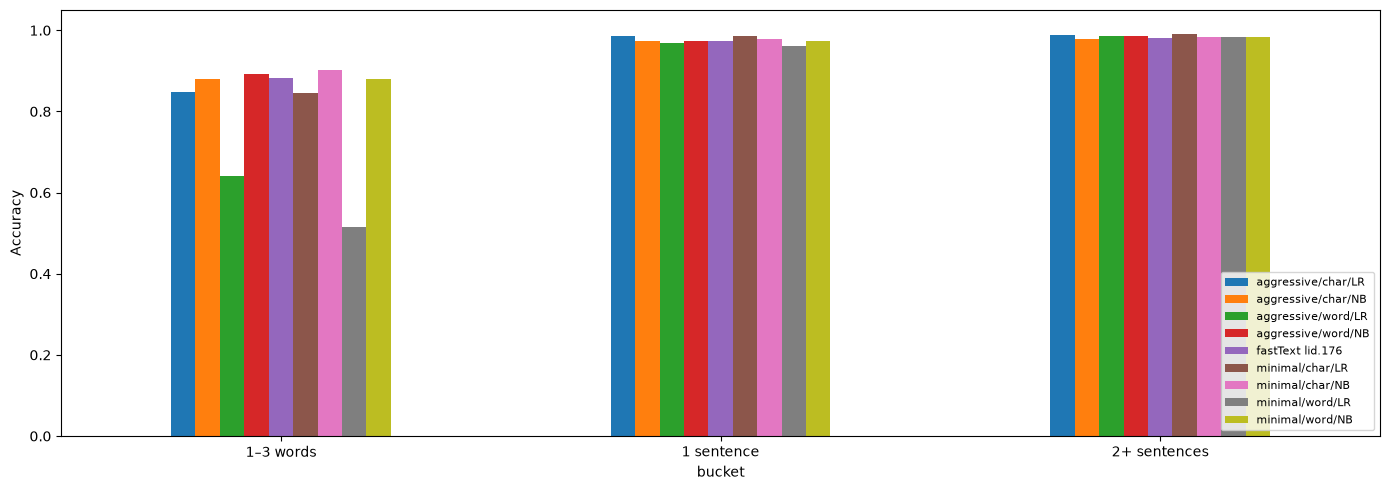

,text,TFIDF_LR,LR_probability_uncalibrated,fastText,fastText_probability_uncalibrated
0,Сегодня очень хорошая погода.,Russian,0.928971,Russian,0.990620
1,The weather is wonderful today.,English,0.848358,English,0.963529
2,Hoy hace muy buen tiempo.,Spanish,0.401194,Spanish,0.999346
3,Hoje o tempo está muito bom.,Portuguese,0.551475,Portuguese,0.977280
4,Il fait très beau aujourd’hui.,French,0.589069,French,0.979288
5,Heute ist das Wetter sehr schön.,German,0.772814,German,0.999564


In [20]:
train_text_keys = set(lang_train.text.map(aggressive_clean))
train_sentence_keys = set()
train_short_keys = set()
for text in lang_train.text:
    for sent in nltk.sent_tokenize(text): train_sentence_keys.add(aggressive_clean(sent))
    train_short_keys.add(aggressive_clean(' '.join(text.split()[:3])))
stress_rows = []
for language, group in lang_test.groupby('label'):
    examples = group.text.tolist()
    for i, text in enumerate(examples):
        sentences = nltk.sent_tokenize(text)
        if not sentences: continue
        variants = [('1–3 words', ' '.join(text.split()[:3]), False),
                    ('1 sentence', sentences[0], False)]
        if len(sentences) >= 2:
            variants.append(('2+ sentences', ' '.join(sentences[:2]), False))
        elif len(examples) > 1:
            other = nltk.sent_tokenize(examples[(i + 1) % len(examples)])[0]
            variants.append(('2+ sentences', sentences[0] + ' ' + other, True))
        for bucket, variant, paired in variants:
            key = aggressive_clean(variant)
            if not key or key in train_text_keys or key in train_sentence_keys or key in train_short_keys: continue
            stress_rows.append({'label': language, 'bucket': bucket, 'text': variant,
                                'paired_test_sentences': paired, 'word_count': len(variant.split())})
stress_data = pd.DataFrame(stress_rows).drop_duplicates(['bucket', 'text'])
stress_predictions = {name: model.predict(stress_data.text) for name, model in language_models.items()}
stress_predictions['fastText lid.176'] = fasttext_predict(stress_data.text)
stress_scores = []
for name, pred in stress_predictions.items():
    for bucket in ['1–3 words', '1 sentence', '2+ sentences']:
        mask = stress_data.bucket == bucket
        if not mask.any(): continue
        stress_scores.append({'model': name, 'bucket': bucket, 'n': int(mask.sum()),
            'mean_words': float(stress_data.loc[mask, 'word_count'].mean()),
            **evaluate(stress_data.loc[mask, 'label'], pred[mask.to_numpy()])})
stress_metrics = pd.DataFrame(stress_scores)
display(stress_metrics)
plot_order = ['1–3 words', '1 sentence', '2+ sentences']
stress_metrics.pivot(index='bucket', columns='model', values='accuracy').reindex(plot_order).plot.bar(figsize=(14, 5))
plt.ylabel('Accuracy'); plt.ylim(0, 1.05); plt.xticks(rotation=0)
plt.legend(loc='lower right', fontsize=8); plt.tight_layout()
plt.savefig(RESULTS / 'task4_length_accuracy.png', dpi=150); plt.show()
save_table(stress_metrics, 'task4_length_metrics.csv')
save_table(stress_data, 'task4_length_examples.csv')

def identify_language(text):
    if not minimal_clean(text): raise ValueError('Введите непустой текст')
    probs = primary_language_model.predict_proba([text])[0]
    classes = primary_language_model.named_steps['classifier'].classes_
    j = int(probs.argmax())
    ft_label, ft_conf = fasttext_predict([text], with_confidence=True)
    return {'text': text, 'TFIDF_LR': classes[j], 'LR_probability_uncalibrated': float(probs[j]),
            'fastText': ft_label[0], 'fastText_probability_uncalibrated': float(ft_conf[0])}
display(pd.DataFrame([identify_language(s) for s in [
    'Сегодня очень хорошая погода.', 'The weather is wonderful today.',
    'Hoy hace muy buen tiempo.', 'Hoje o tempo está muito bom.',
    'Il fait très beau aujourd’hui.', 'Heute ist das Wetter sehr schön.']]))

**Вывод по языкам.** Символьные n-граммы умеют использовать характерные буквы и окончания,
а словарная TF-IDF сильнее зависит от наличия знакомых слов. На коротких строках мало
сигналов; похожие языки и имена делают задачу неоднозначной. Для выводов именно об этой
выборке смотрите рассчитанные accuracy/macro F1 и график выше. Основной классификатор
обучен только на шести языках: при вводе казахского или другого неизвестного языка он всё
равно выберет один из шести. fastText распознаёт больше языков. Для рабочего сервиса нужны
неизвестный класс, калибровка вероятностей и отдельная проверка на шуме и новых источниках.

## Ответы на контрольные вопросы

1. **Extractive и abstractive:** извлечение выбирает исходные предложения; генерация
   формулирует новый текст, который может перефразировать и объединять факты.
2. **Почему TF-IDF/GraphRank выбирают предложения?** В summarization единицами ранжирования
   задаются предложения: TF-IDF оценивает их содержание, графовый метод — связи между ними.
   Отдельные слова не образуют готовую связную аннотацию. Сам TF-IDF не ограничен предложениями.
3. **Сложности генерации:** длинный контекст, сохранение главного, фактические ошибки,
   повторы, неправильные связи между фрагментами, недостаток качественных эталонов.
4. **ROUGE:** семейство метрик совпадения с эталонной сводкой: ROUGE-1/2 — униграммы/биграммы,
   ROUGE-L — наибольшая общая подпоследовательность. Обычно считают precision, recall и F1;
   хорошее совпадение не гарантирует верность фактов и может недооценить корректный парафраз.
5. **Зачем грамматика при генерации?** Новые формулировки должны сохранять однозначный смысл,
   правильные связи и ссылки на сущности; иначе даже верные слова могут выражать неверный факт.
6. **Словарь и ML:** словарный метод использует заранее заданные оценки слов и правила;
   ML изучает закономерности размеченных примеров. Первый проще интерпретировать,
   второй адаптируется к домену, но зависит от качества и распределения обучения.
7. **Лемматизация:** приводит словоформы к словарной форме (`eyes → eye`), уменьшает
   разреженность и объединяет частоты. Может потерять грамматические различия и ошибиться без контекста.
8. **Confusion matrix:** строки — истинные, столбцы — предсказанные классы; диагональ —
   верные ответы, остальные ячейки показывают конкретные направления ошибок.
9. **Почему accuracy вводит в заблуждение?** При дисбалансе постоянный прогноз большинства
   даёт высокий результат, но игнорирует редкие классы. Нужны per-class precision/recall,
   macro F1, матрица ошибок и сравнение с majority baseline.
10. **Что мешает тональности?** Сарказм, отрицания, смешанные оценки, многозначность,
    сленг, доменные значения, эмодзи, опечатки, мало контекста и ошибки разметки.
11. **Нормализация и стандартизация:** для числовых признаков нормализация может означать
    масштабирование в [0,1] или приведение вектора к единичной норме; стандартизация обычно
    означает `(x − mean) / std`. В NLP нормализация текста — другой термин: регистр, Unicode,
    леммы и т.д. Параметры числовых преобразований оценивают только на train.
12. **TF-IDF против частот:** уменьшает вклад слов, частых во всём корпусе, и подчёркивает
    слова, отличающие конкретный документ. Типичный вес — `tf(t,d) * log(N/df(t))`;
    реализации могут использовать сглаживание и нормирование.
13. **Почему генераторы ошибаются грамматически?** Предсказывают последовательность токенов
    статистически, без строгого грамматического доказательства; мешают доменный сдвиг,
    длинные зависимости, ошибки обучающих текстов и ограничения декодирования.
14. **ROC и Precision–Recall:** ROC показывает TPR против FPR при разных порогах;
    PR — precision против recall. Для редкого положительного класса PR часто информативнее:
    FPR может оставаться малым при большом числе ложных срабатываний. Для нескольких классов
    используют one-vs-rest и явный способ усреднения.
15. **Bag-of-Words:** документ — вектор количеств/наличия слов из словаря; порядок слов
    не учитывается. N-граммы частично добавляют локальный порядок. Словарь строят на train,
    чтобы не использовать сведения из test.

In [21]:
# Сохраняем происхождение данных, версии и сводный отчёт.
packages = ['numpy', 'pandas', 'scikit-learn', 'nltk', 'transformers', 'torch',
            'optimum', 'onnxruntime', 'fasttext-wheel', 'wordcloud', 'rouge-score']
versions = {p: importlib.metadata.version(p) for p in packages}
manifest = {'seed': SEED, 'python': sys.version, 'packages': versions, 'downloads': DOWNLOAD_LOG,
            'task1_split': {'train': len(sent_train), 'validation': len(sent_val), 'test': len(sent_test)},
            'task3_songs': lyrics_sample.groupby('genre').size().to_dict(),
            'task4_split': {'train': len(lang_train), 'test': len(lang_test)},
            'article_sha256': {n: hashlib.sha256(t.encode()).hexdigest() for n, t in documents.items()}}
(RESULTS / 'run_manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.Series(versions, name='version').to_frame())
display(Markdown('### Выполнение завершено'))
print('Результаты:', RESULTS.resolve())
print('Сохранено файлов:', len(list(RESULTS.iterdir())))
print('Task 1: test examples =', len(sent_test))
print('Task 2: 3 × 3 extractive sentences; 6 combined; all 5 documents summarized')
print('Task 3:', lyrics_sample.groupby('genre').size().to_dict())
print('Task 4: 8 classical models + pretrained fastText; test examples =', len(lang_test))

,version
numpy,1.26.4
pandas,2.2.3
scikit-learn,1.5.2
nltk,3.9.1
transformers,4.46.3
torch,2.5.1+cpu
optimum,1.23.3
onnxruntime,1.20.1
fasttext-wheel,0.9.2
wordcloud,1.9.6


### Выполнение завершено

Результаты: /workspace/output/nlp_assignment_results
Сохранено файлов: 31
Task 1: test examples = 2797
Task 2: 3 × 3 extractive sentences; 6 combined; all 5 documents summarized
Task 3: {'blues': 10, 'country': 10, 'folk': 10, 'hip-hop': 10}
Task 4: 8 classical models + pretrained fastText; test examples = 960
